# Predicting Industrial Machine Downtime: Level 3

## 📖 Background
You work for a manufacturer of high-precision metal components used in aerospace, automotives, and medical device applications. Your company operates three different machines on its shop floor that produce different sized components, so minimizing the downtime of these machines is vital for meeting production deadlines.

Your team wants to use a data-driven approach to predicting machine downtime, so proactive maintenance can be planned rather than being reactive to machine failure. To support this, your company has been collecting operational data for over a year and whether each machine was down at those times.

In this third level, you're going to develop a predictive model that could be combined with real-time operational data to detect likely machine failure. 

## 💾 The data

The company has stored the machine operating data in a single table, available in `'data/machine_downtime.csv'`.

#### Each row in the table represents the operational data for a single machine on a given day:
- `"Date"` - the date the reading was taken on.
- `"Machine_ID"` - the unique identifier of the machine being read.
- `"Assembly_Line_No"` - the unique identifier of the assembly line the machine is located on.
- `"Hydraulic_Pressure(bar)"`, `"Coolant_Pressure(bar)"`, and `"Air_System_Pressure(bar)"` - pressure measurements at different points in the machine.
- `"Coolant_Temperature"`, `"Hydraulic_Oil_Temperature"`, and `"Spindle_Bearing_Temperature"` - temperature measurements (in Celsius) at different points in the machine.
- `"Spindle_Vibration"`, `"Tool_Vibration"`, and `"Spindle_Speed(RPM)"` - vibration (measured in micrometers) and rotational speed measurements for the spindle and tool.
- `"Voltage(volts)"` - the voltage supplied to the machine.
- `"Torque(Nm)"` - the torque being generated by the machine.
- `"Cutting(KN)"` - the cutting force of the tool.
- `"Downtime"` - an indicator of whether the machine was down or not on the given day.

In [217]:
import pandas as pd
downtime = pd.read_csv('data/machine_downtime.csv')
downtime.head()

,Date,Machine_ID,Assembly_Line_No,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature,Spindle_Bearing_Temperature,Spindle_Vibration,Tool_Vibration,Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Downtime
0,31-12-2021,Makino-L1-Unit1-2013,Shopfloor-L1,71.04,6.933725,6.284965,25.6,46.0,33.4,1.291,26.492,25892.0,335.0,24.055326,3.58,Machine_Failure
1,31-12-2021,Makino-L1-Unit1-2013,Shopfloor-L1,125.33,4.936892,6.196733,35.3,47.4,34.6,1.382,25.274,19856.0,368.0,14.202890,2.68,Machine_Failure
2,31-12-2021,Makino-L3-Unit1-2015,Shopfloor-L3,71.12,6.839413,6.655448,13.1,40.7,33.0,1.319,30.608,19851.0,325.0,24.049267,3.55,Machine_Failure
3,31-05-2022,Makino-L2-Unit1-2015,Shopfloor-L2,139.34,4.574382,6.560394,24.4,44.2,40.6,0.618,30.791,18461.0,360.0,25.860029,3.55,Machine_Failure
4,31-03-2022,Makino-L1-Unit1-2013,Shopfloor-L1,60.51,6.893182,6.141238,4.1,47.3,31.4,0.983,25.516,26526.0,354.0,25.515874,3.55,Machine_Failure


In [218]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Data Validation

This dataset contains 2500 rows and 16 columns.

- Date: originally had an 'object' data type and was changed to 'datetime'. The date the reading was taken on. I created an additional column 'Month' with categorical data type. Without missing values.
- Machine_ID: originally had an 'object' data type and was changed to 'category'. The unique identifier of the machine being read. Without missing values.
- Assembly_Line_No: originally had an 'object' data type and was changed to 'category'. The unique identifier of the assembly line the machine is located on. Without missing values.
- The twelve measurement columns are all 'float' and all have a few missing values: Hydraulic_Pressure(bar) 10, Coolant_Pressure(bar) 19, Air_System_Pressure(bar) 17, Coolant_Temperature 12, Hydraulic_Oil_Temperature 16, Spindle_Bearing_Temperature 7, Spindle_Vibration 11, Tool_Vibration 11, Spindle_Speed(RPM) 6, Voltage(volts) 6, Torque(Nm) 21 and Cutting(kN) 7. I do not fill them at this step. They are filled inside the model pipeline, so the filling values are calculated on the training data only.
- Downtime: originally had an 'object' data type. Later I mapped it to 1 for 'Machine_Failure' and 0 for 'No_Machine_Failure'. Without missing values.

There is also one negative value in 'Hydraulic_Pressure(bar)' and one in 'Spindle_Vibration'. These measurements cannot be negative, so I turned them into NaN and let the pipeline fill them together with the rest.

In [219]:
# check the data types
downtime.dtypes

Date                            object
Machine_ID                      object
Assembly_Line_No                object
Hydraulic_Pressure(bar)        float64
Coolant_Pressure(bar)          float64
Air_System_Pressure(bar)       float64
Coolant_Temperature            float64
Hydraulic_Oil_Temperature      float64
Spindle_Bearing_Temperature    float64
Spindle_Vibration              float64
Tool_Vibration                 float64
Spindle_Speed(RPM)             float64
Voltage(volts)                 float64
Torque(Nm)                     float64
Cutting(kN)                    float64
Downtime                        object
dtype: object

In [220]:
# check for missing values
downtime.isna().sum()

Date                            0
Machine_ID                      0
Assembly_Line_No                0
Hydraulic_Pressure(bar)        10
Coolant_Pressure(bar)          19
Air_System_Pressure(bar)       17
Coolant_Temperature            12
Hydraulic_Oil_Temperature      16
Spindle_Bearing_Temperature     7
Spindle_Vibration              11
Tool_Vibration                 11
Spindle_Speed(RPM)              6
Voltage(volts)                  6
Torque(Nm)                     21
Cutting(kN)                     7
Downtime                        0
dtype: int64

In [221]:
# describe numerical columns
downtime.describe()

,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature,Spindle_Bearing_Temperature,Spindle_Vibration,Tool_Vibration,Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN)
count,2490.000000,2481.000000,2483.000000,2488.000000,2484.000000,2493.000000,2489.000000,2489.000000,2494.000000,2494.000000,2479.000000,2493.000000
mean,101.409084,4.947058,6.499275,18.559887,47.618317,35.063698,1.009334,25.411975,20274.792302,348.996792,25.234968,2.782551
std,30.289301,0.997357,0.407279,8.554480,3.768674,3.764823,0.342898,6.437142,3852.660056,45.376024,6.138564,0.616688
min,-14.326454,0.325000,5.063480,4.100000,35.200000,22.600000,-0.461000,2.161000,0.000000,202.000000,0.000000,1.800000
25%,76.355000,4.462464,6.217987,10.400000,45.100000,32.500000,0.777000,21.089000,17919.000000,319.000000,21.666115,2.250000
50%,96.763486,4.939960,6.505191,21.200000,47.700000,35.100000,1.008000,25.455000,20137.500000,349.000000,24.647736,2.780000
75%,126.415727,5.518401,6.780550,25.600000,50.100000,37.600000,1.236000,29.790000,22501.750000,380.000000,30.514008,3.270000
max,191.000000,11.350000,7.973992,98.200000,61.400000,49.500000,2.000000,45.726000,27957.000000,479.000000,55.552400,3.930000


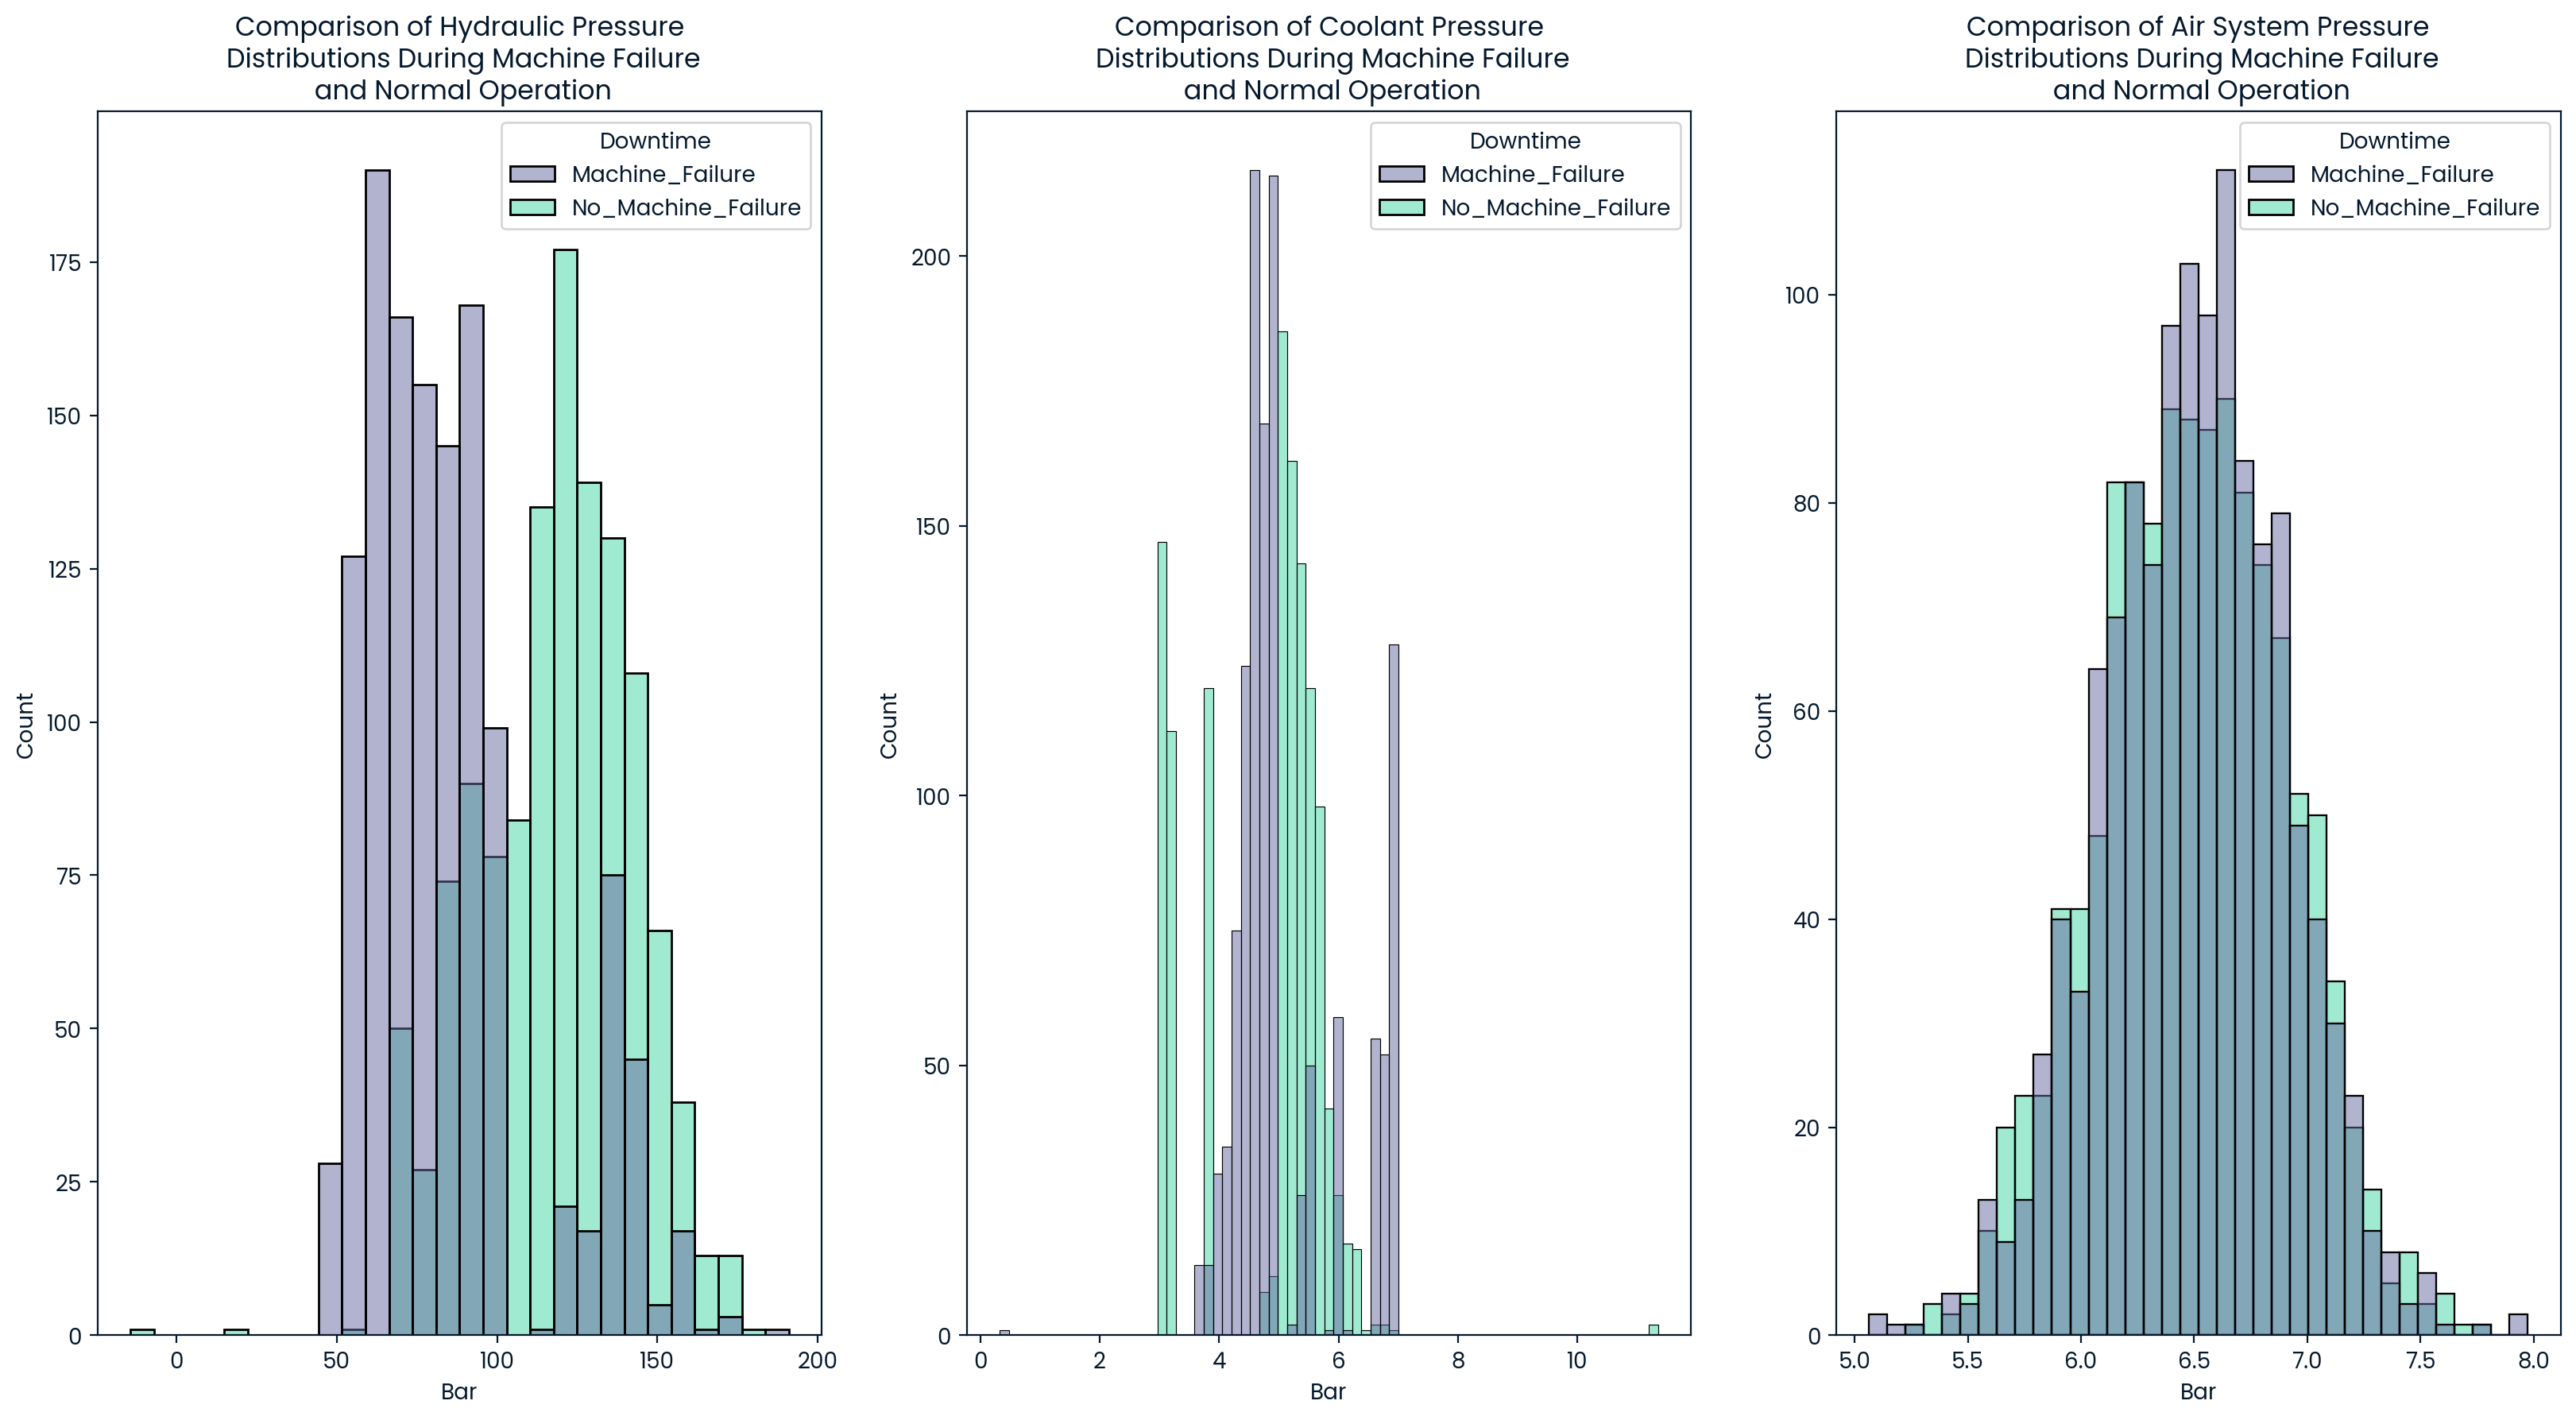

In [222]:
# check the distributions of numerical columns
pressure_cols = ['Hydraulic_Pressure(bar)', 'Coolant_Pressure(bar)', 'Air_System_Pressure(bar)']

fig, axes = plt.subplots(1, 3, figsize=(20,10))
for i, col in enumerate(pressure_cols):
    sns.histplot(data=downtime, x=col, hue='Downtime', ax=axes[i])
    axes[0].set_title('Comparison of Hydraulic Pressure\n Distributions During Machine Failure\n and Normal Operation')
    axes[1].set_title('Comparison of Coolant Pressure\n Distributions During Machine Failure\n and Normal Operation')
    axes[2].set_title('Comparison of Air System Pressure\n Distributions During Machine Failure\n and Normal Operation')
    axes[0].set_xlabel('Bar')
    axes[1].set_xlabel('Bar')
    axes[2].set_xlabel('Bar')
plt.show()

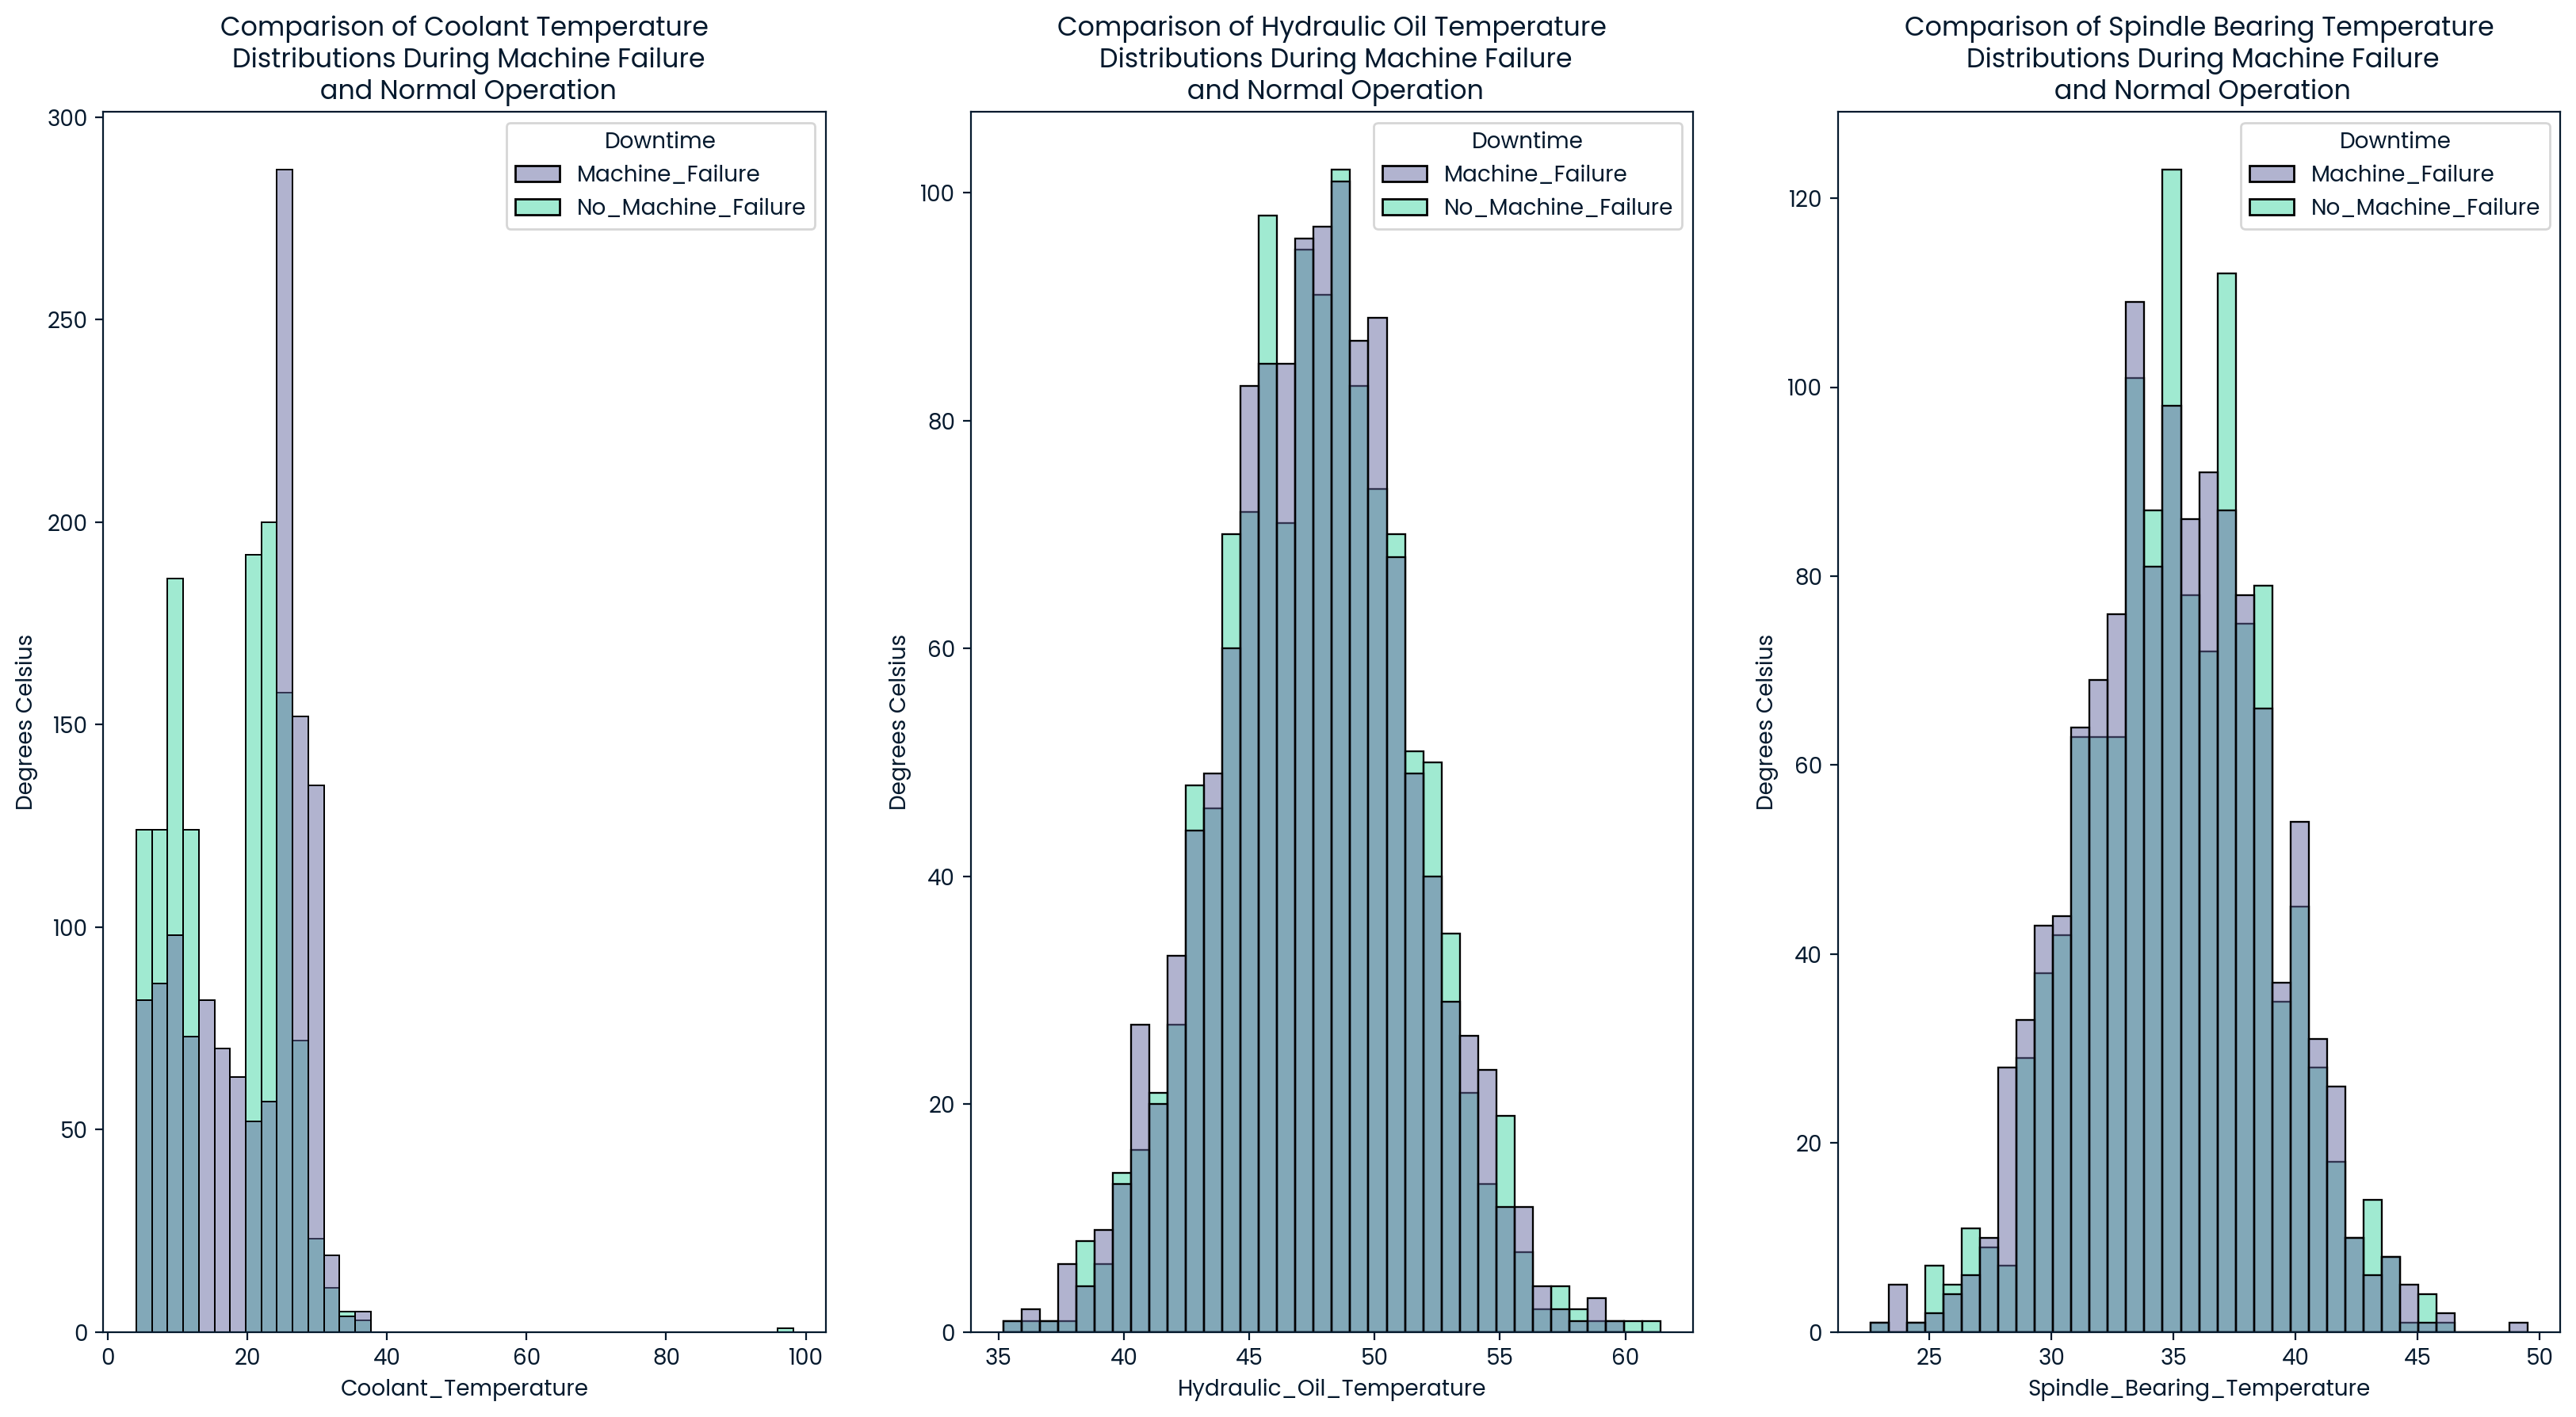

In [223]:
# check the distributions of numerical columns
temperature_cols = ['Coolant_Temperature', 'Hydraulic_Oil_Temperature', 'Spindle_Bearing_Temperature']

fig, axes = plt.subplots(1, 3, figsize=(20,10))
for i, col1 in enumerate(temperature_cols):
    sns.histplot(data=downtime, x=col1, hue='Downtime', ax=axes[i])
    axes[0].set_title('Comparison of Coolant Temperature\n Distributions During Machine Failure\n and Normal Operation')
    axes[1].set_title('Comparison of Hydraulic Oil Temperature\n Distributions During Machine Failure\n and Normal Operation')
    axes[2].set_title('Comparison of Spindle Bearing Temperature\n Distributions During Machine Failure\n and Normal Operation')
    axes[0].set_ylabel('Degrees Celsius')
    axes[1].set_ylabel('Degrees Celsius')
    axes[2].set_ylabel('Degrees Celsius')
plt.show()

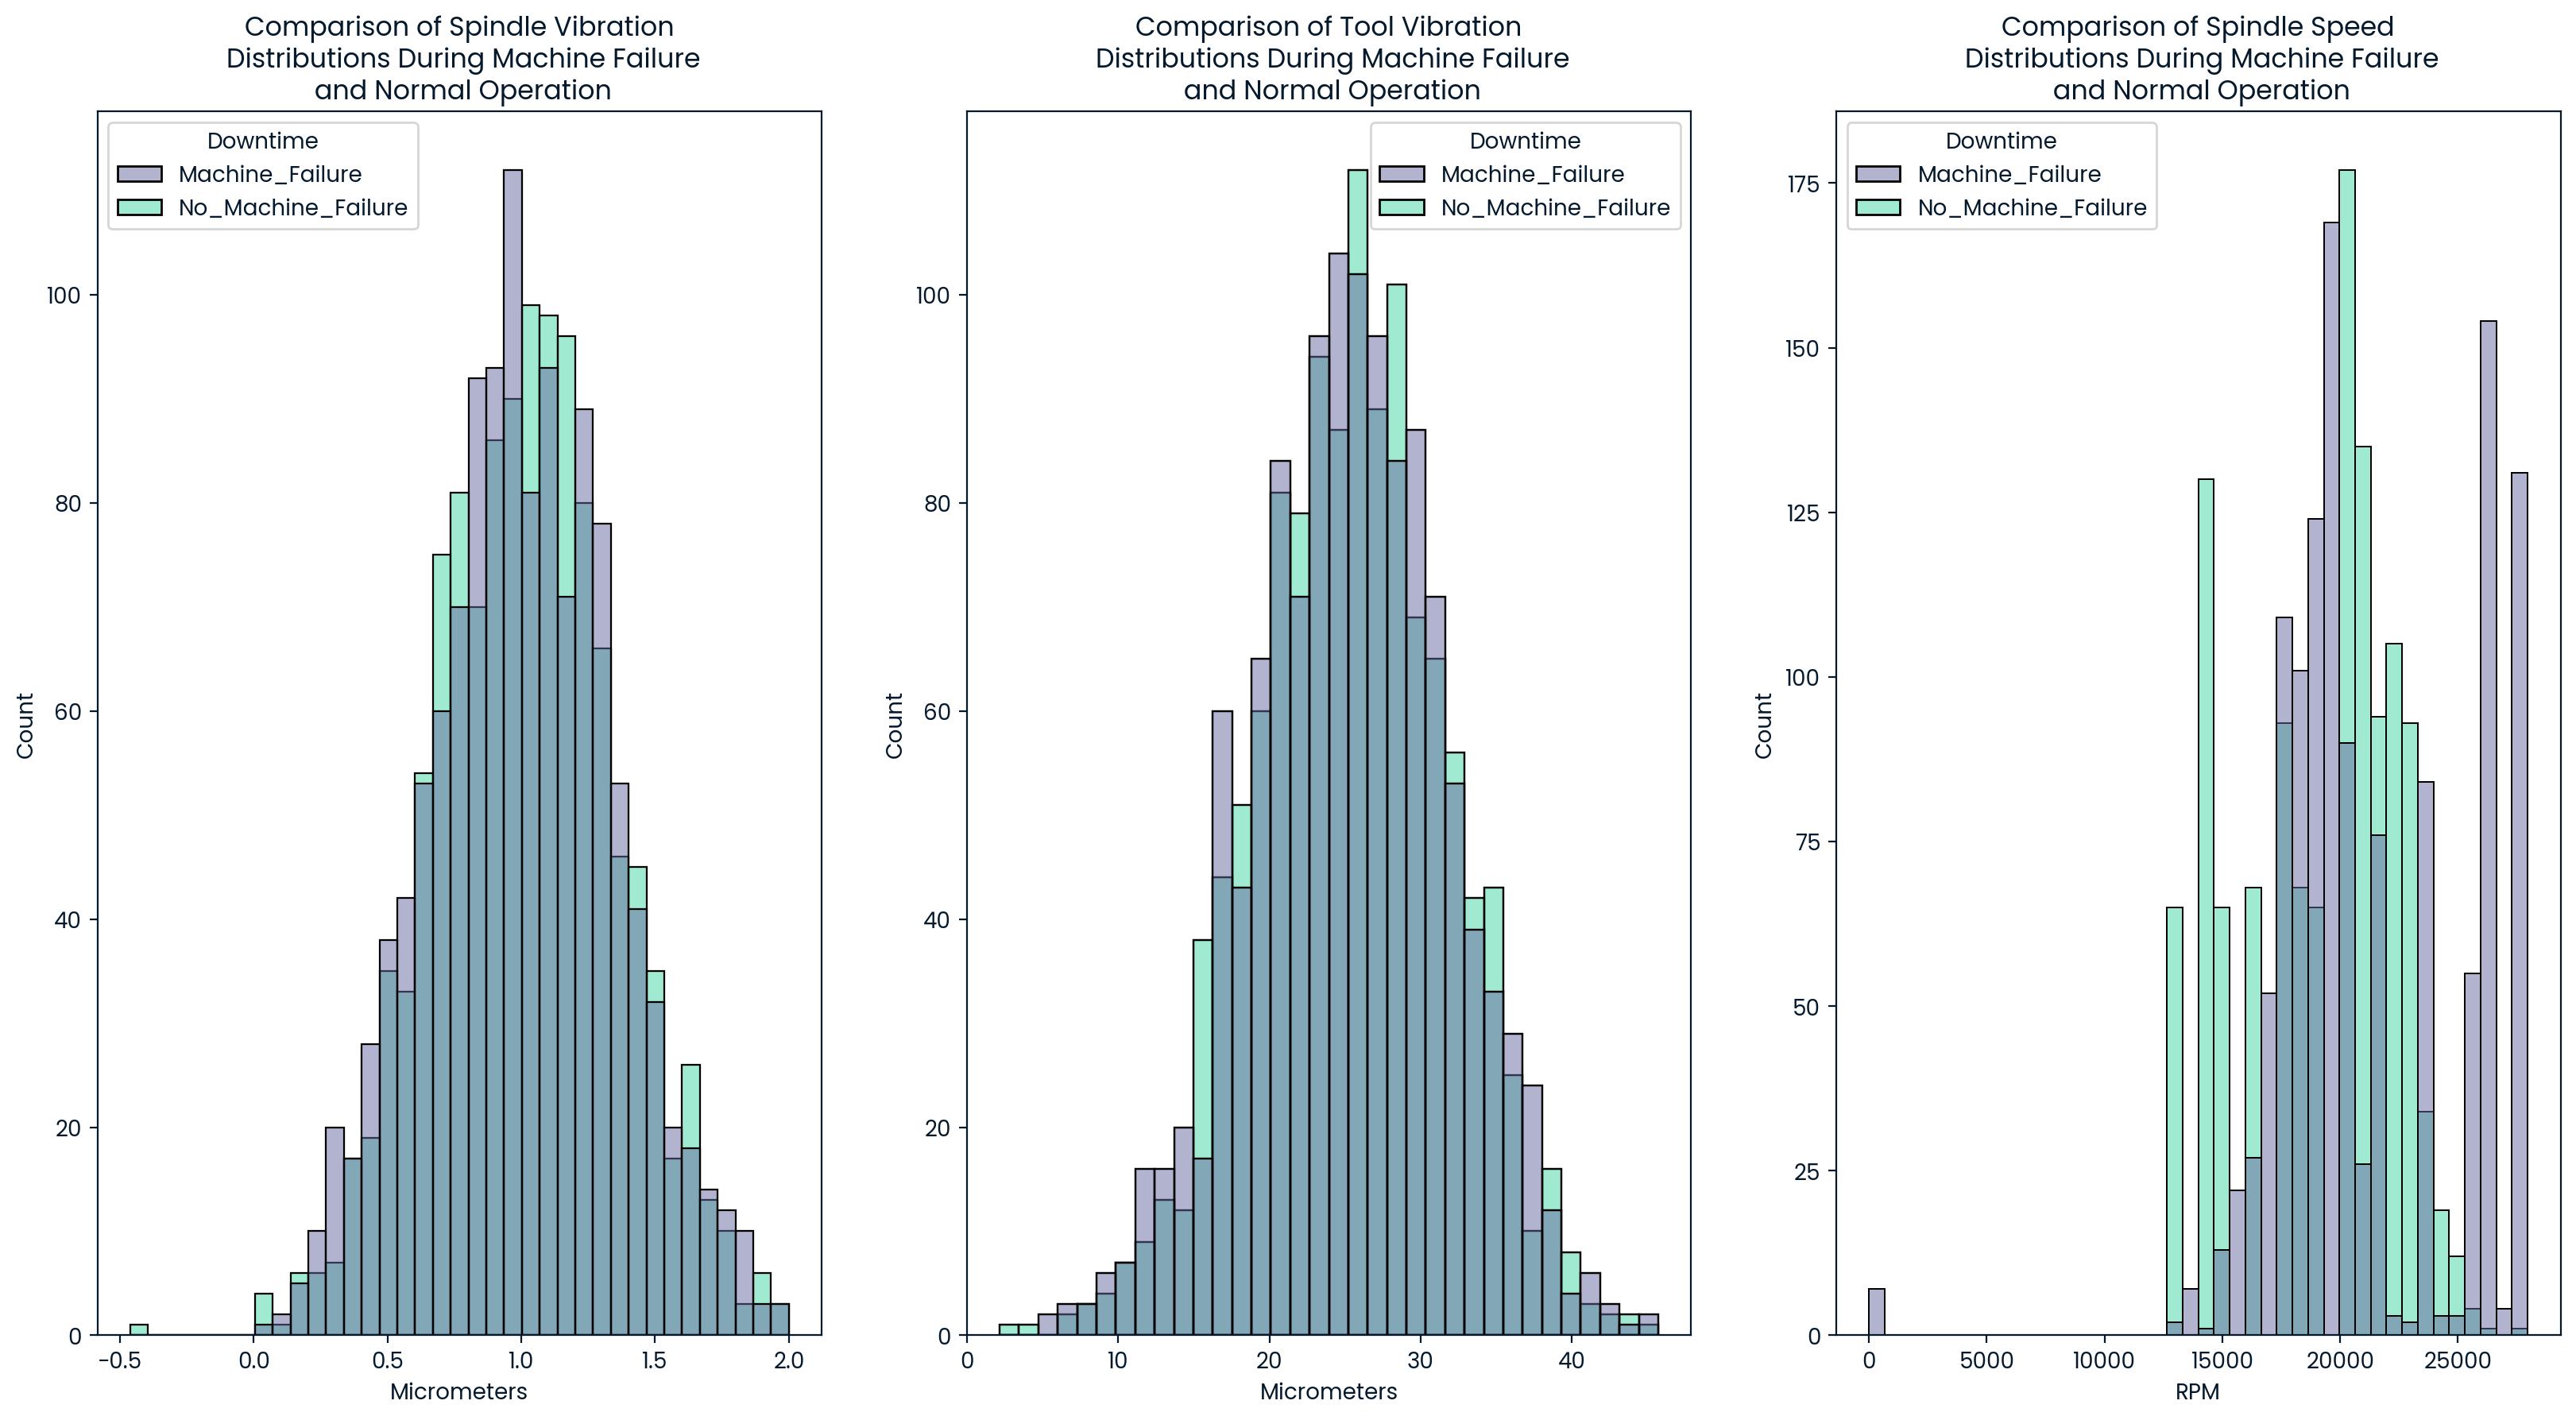

In [224]:
# check the distributions of numerical columns
speed_and_vibration_cols = ['Spindle_Vibration', 'Tool_Vibration', 'Spindle_Speed(RPM)']

fig, axes = plt.subplots(1, 3, figsize=(20,10))
for i, col2 in enumerate(speed_and_vibration_cols):
    sns.histplot(data=downtime, x=col2, hue='Downtime', ax=axes[i])
    axes[0].set_title('Comparison of Spindle Vibration\n Distributions During Machine Failure\n and Normal Operation')
    axes[1].set_title('Comparison of Tool Vibration\n Distributions During Machine Failure\n and Normal Operation')
    axes[2].set_title('Comparison of Spindle Speed\n Distributions During Machine Failure\n and Normal Operation')
    axes[0].set_xlabel('Micrometers')
    axes[1].set_xlabel('Micrometers')
    axes[2].set_xlabel('RPM')
plt.show()

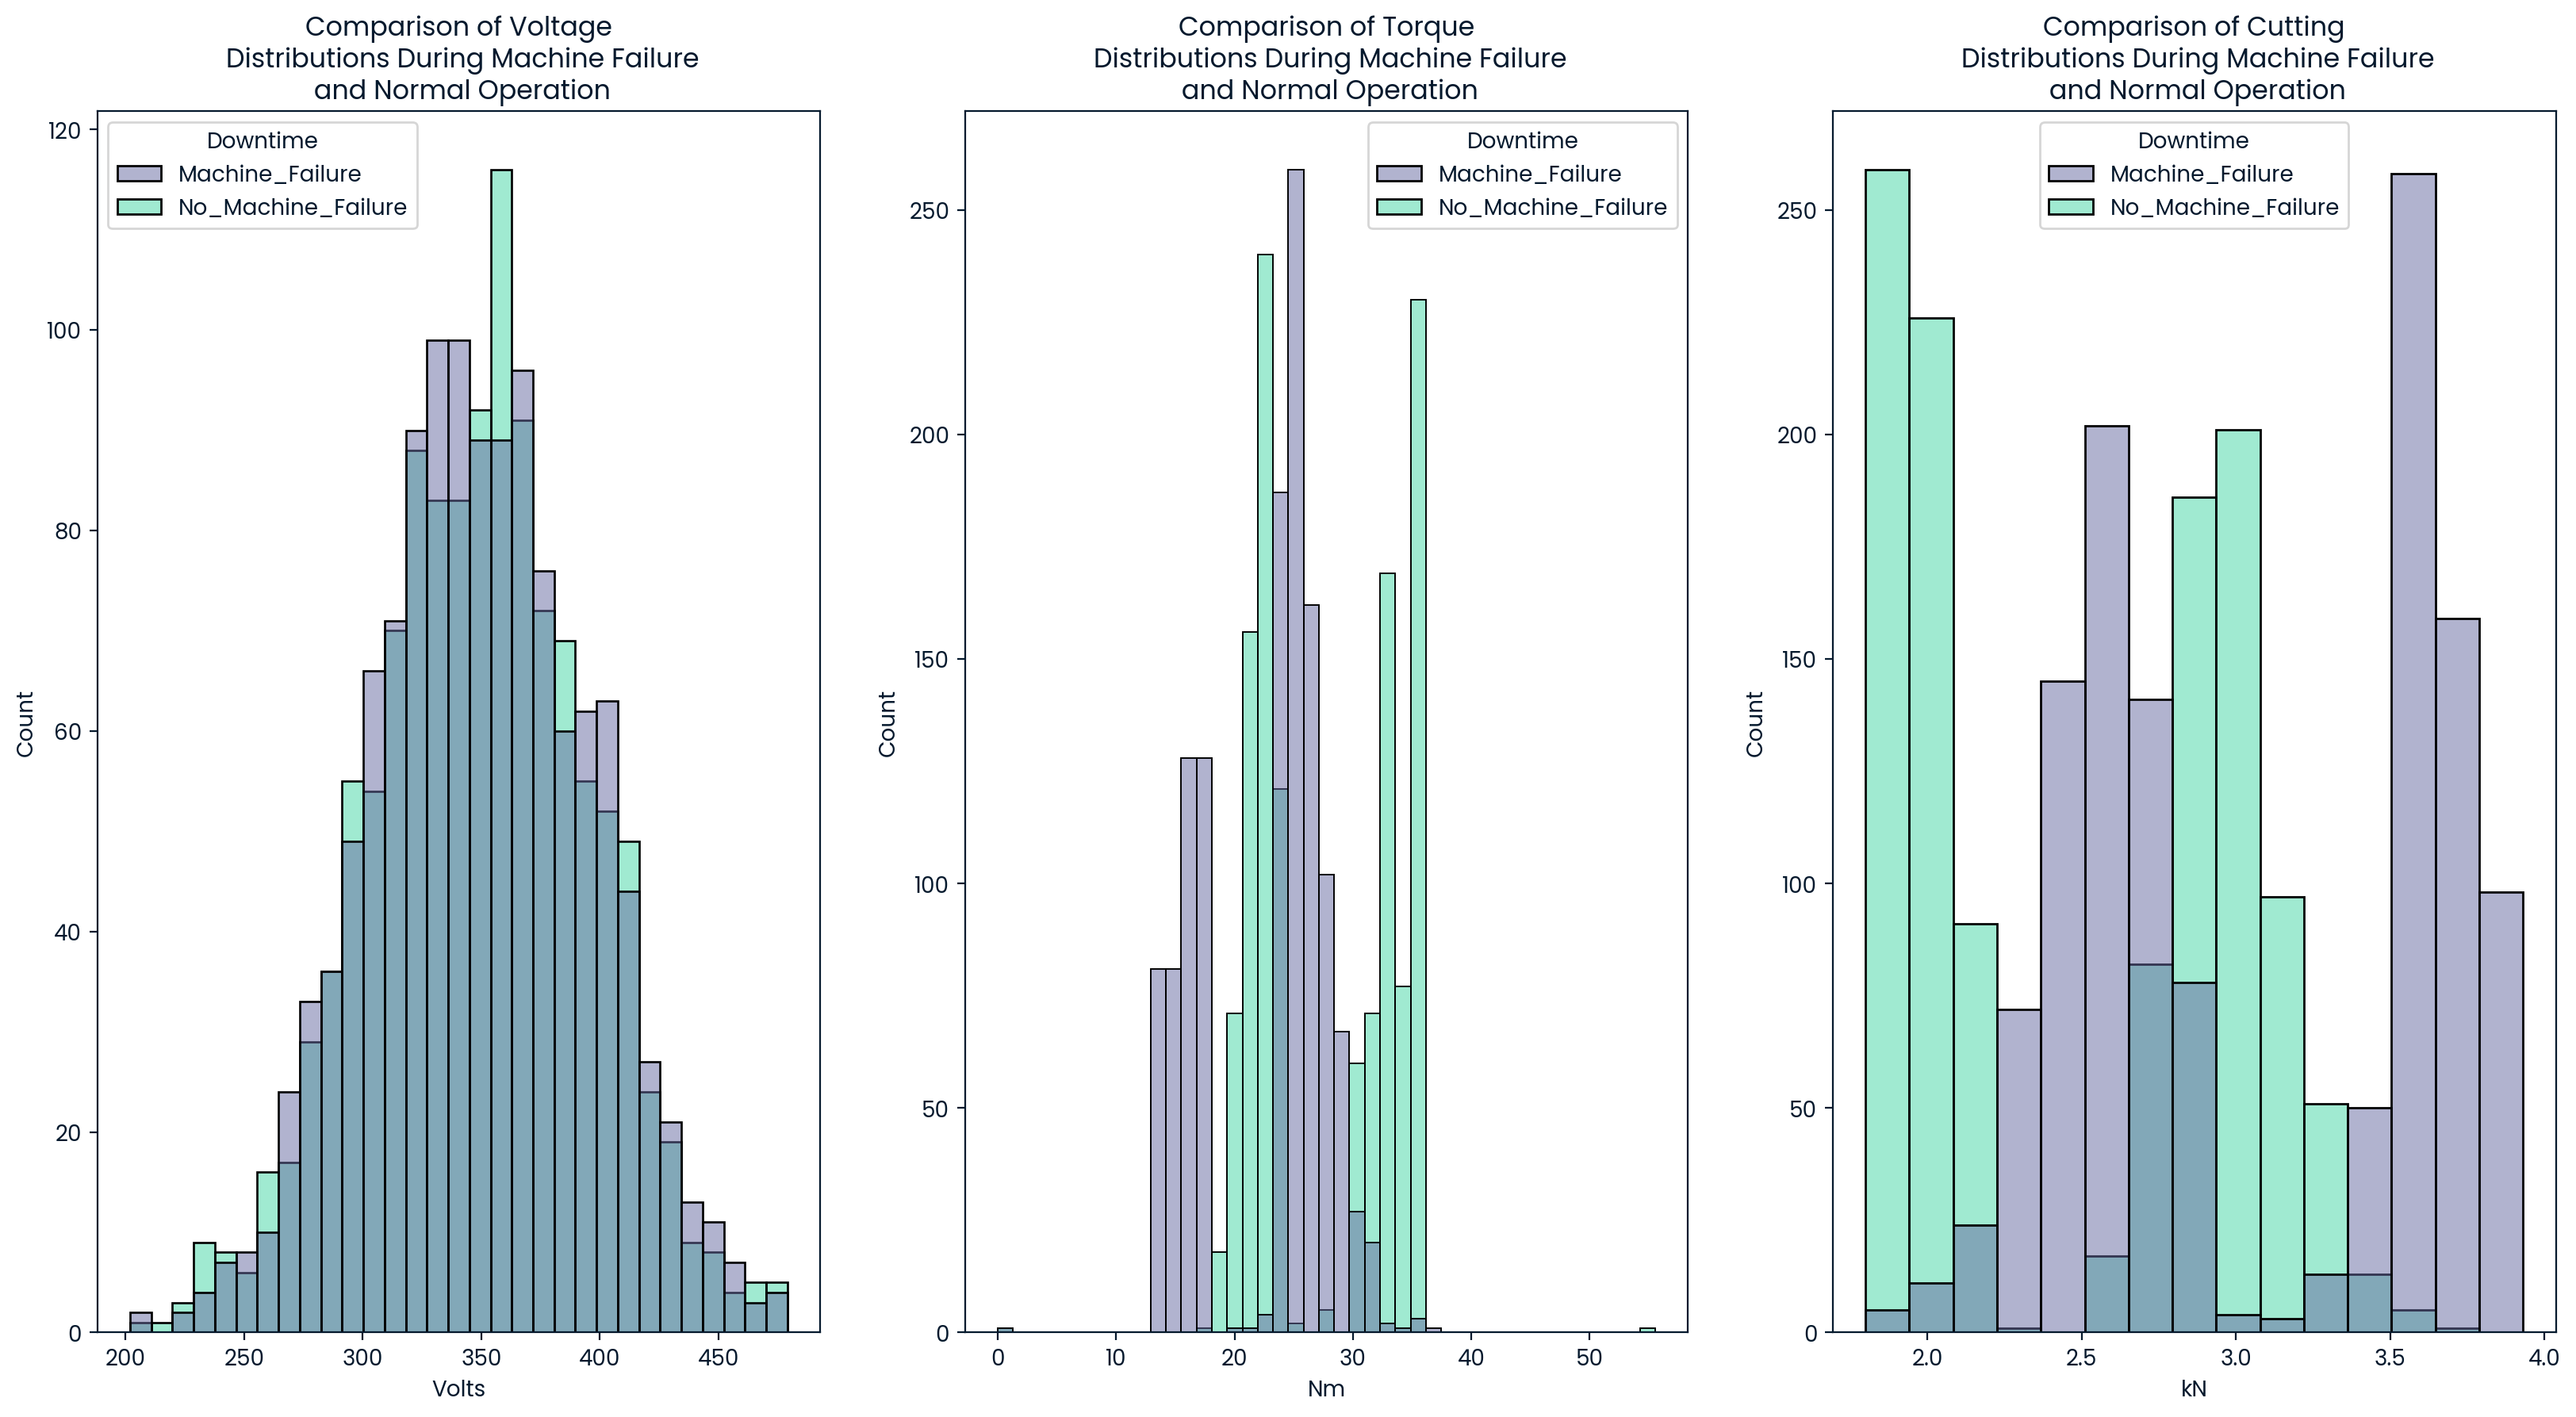

In [225]:
# check the distributions of numerical columns
voltage_torgue_cutting_cols = ['Voltage(volts)', 'Torque(Nm)', 'Cutting(kN)']

fig, axes = plt.subplots(1, 3, figsize=(20,10))
for i, col3 in enumerate(voltage_torgue_cutting_cols):
    sns.histplot(data=downtime, x=col3, hue='Downtime', ax=axes[i])
    axes[0].set_title('Comparison of Voltage\n Distributions During Machine Failure\n and Normal Operation')
    axes[1].set_title('Comparison of Torque\n Distributions During Machine Failure\n and Normal Operation')
    axes[2].set_title('Comparison of Cutting\n Distributions During Machine Failure\n and Normal Operation')
    axes[0].set_xlabel('Volts')
    axes[1].set_xlabel('Nm')
    axes[2].set_xlabel('kN')
plt.show()

In the information above, we observe negative values in two columns: Hydraulic_Pressure(bar) and Spindle_Vibration. These values cannot be negative, so I replaced them with NaN. I do not fill them here — they are filled later inside the model pipeline, together with all the other missing values.

In [226]:
# Cleaning that does NOT touch the target 
downtime_clean = downtime.copy()

# Physically impossible values -> NaN
downtime_clean.loc[downtime_clean['Hydraulic_Pressure(bar)'] < 0,
                   'Hydraulic_Pressure(bar)'] = np.nan
downtime_clean.loc[downtime_clean['Spindle_Vibration'] < 0,
                   'Spindle_Vibration'] = np.nan

print("NaN left (they will be filled inside the pipeline, on train only):")
print(downtime_clean.isna().sum()[lambda s: s > 0])

NaN left (they will be filled inside the pipeline, on train only):
Hydraulic_Pressure(bar)        11
Coolant_Pressure(bar)          19
Air_System_Pressure(bar)       17
Coolant_Temperature            12
Hydraulic_Oil_Temperature      16
Spindle_Bearing_Temperature     7
Spindle_Vibration              12
Tool_Vibration                 11
Spindle_Speed(RPM)              6
Voltage(volts)                  6
Torque(Nm)                     21
Cutting(kN)                     7
dtype: int64


In [227]:
# change the data types of columns: 'Date', 'Machine_ID', 'Assembly_Line_No', 'Downtime'
downtime_clean['Date'] = pd.to_datetime(downtime_clean['Date'], dayfirst=True)
downtime_clean['Machine_ID'] = downtime_clean['Machine_ID'].astype('category')
downtime_clean['Assembly_Line_No'] = downtime_clean['Assembly_Line_No'].astype('category')

In [228]:
# check the shape of dataset
print("Shape of dataset:", downtime_clean.shape)

# check for missing values
print("\nMissing values in each column:\n", downtime_clean.isna().sum())

# check the data types
print("\nData types:\n", downtime_clean.dtypes)

# check the range of consistency
print("\nDescriptive statistics:\n", downtime_clean.describe())

# check for duplicates
duplicate_rows = downtime_clean[downtime_clean.duplicated()]
print("\nNumber of duplicate rows:\n", duplicate_rows.shape[0])

# class balance
print("\nClass distribution:\n", downtime_clean['Downtime'].value_counts())

Shape of dataset: (2500, 16)

Missing values in each column:
 Date                            0
Machine_ID                      0
Assembly_Line_No                0
Hydraulic_Pressure(bar)        11
Coolant_Pressure(bar)          19
Air_System_Pressure(bar)       17
Coolant_Temperature            12
Hydraulic_Oil_Temperature      16
Spindle_Bearing_Temperature     7
Spindle_Vibration              12
Tool_Vibration                 11
Spindle_Speed(RPM)              6
Voltage(volts)                  6
Torque(Nm)                     21
Cutting(kN)                     7
Downtime                        0
dtype: int64

Data types:
 Date                           datetime64[ns]
Machine_ID                           category
Assembly_Line_No                     category
Hydraulic_Pressure(bar)               float64
Coolant_Pressure(bar)                 float64
Air_System_Pressure(bar)              float64
Coolant_Temperature                   float64
Hydraulic_Oil_Temperature             float64

# Exploratory Data Analysis

### Target variable Downtime

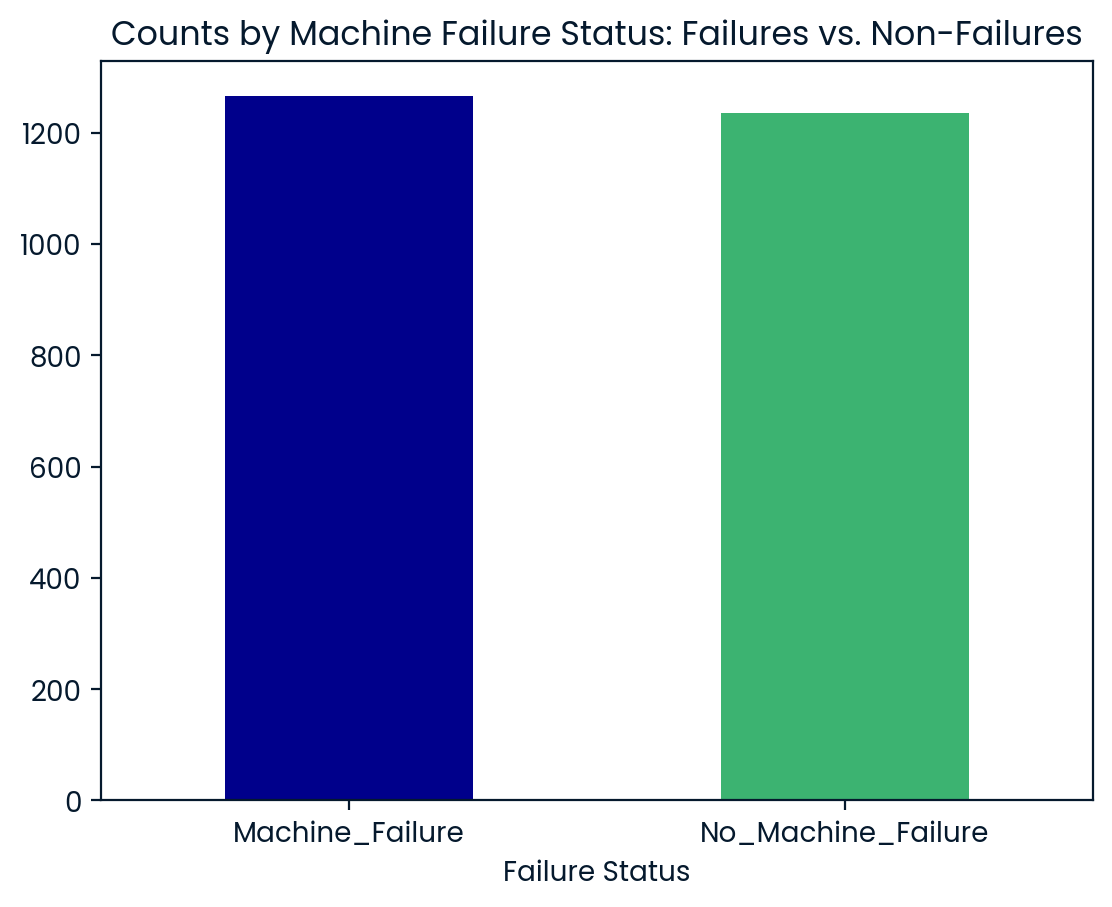

In [229]:
# visualize target variable
counts = downtime_clean['Downtime'].value_counts()
counts.plot(kind='bar', color=['darkblue', 'mediumseagreen'])
plt.title('Counts by Machine Failure Status: Failures vs. Non-Failures')
plt.xticks(rotation=0)
plt.xlabel('Failure Status')
plt.show()

From the plot and information above, we can see that there are 1265 instances of Machine Failure and 1235 instances of No Machine Failure. This suggests that the dataset is not perfectly balanced, but it's quite close.

In [230]:
# data frame containing machine failure cases
machine_failure = downtime_clean[downtime_clean['Downtime'] == 'Machine_Failure']

In [231]:
# extract 'month' and 'year' from 'Date' column
machine_failure['month'] = machine_failure['Date'].dt.month
machine_failure['year'] = machine_failure['Date'].dt.year

In [232]:
# count of failures in each month
machine_failure_month = machine_failure.groupby(['year', 'month']).size().reset_index(name='count')
machine_failure_month['year_month'] = machine_failure_month['month'].astype(str) + '-' + machine_failure_month['year'].astype(str)
cat_order = ['11-2021', '12-2021', '1-2022', '2-2022', '3-2022', '4-2022', '5-2022', '6-2022', '7-2022']
year_month_dtype = pd.CategoricalDtype(categories=cat_order, ordered=True)
machine_failure_month['year_month'] = machine_failure_month['year_month'].astype(year_month_dtype)

In [233]:
# check the data types
machine_failure_month.dtypes

year             int32
month            int32
count            int64
year_month    category
dtype: object

In [234]:
# check the data frame
machine_failure_month

,year,month,count,year_month
0,2021,11,1,11-2021
1,2021,12,13,12-2021
2,2022,1,87,1-2022
3,2022,2,296,2-2022
4,2022,3,533,3-2022
5,2022,4,280,4-2022
6,2022,5,50,5-2022
7,2022,6,4,6-2022
8,2022,7,1,7-2022


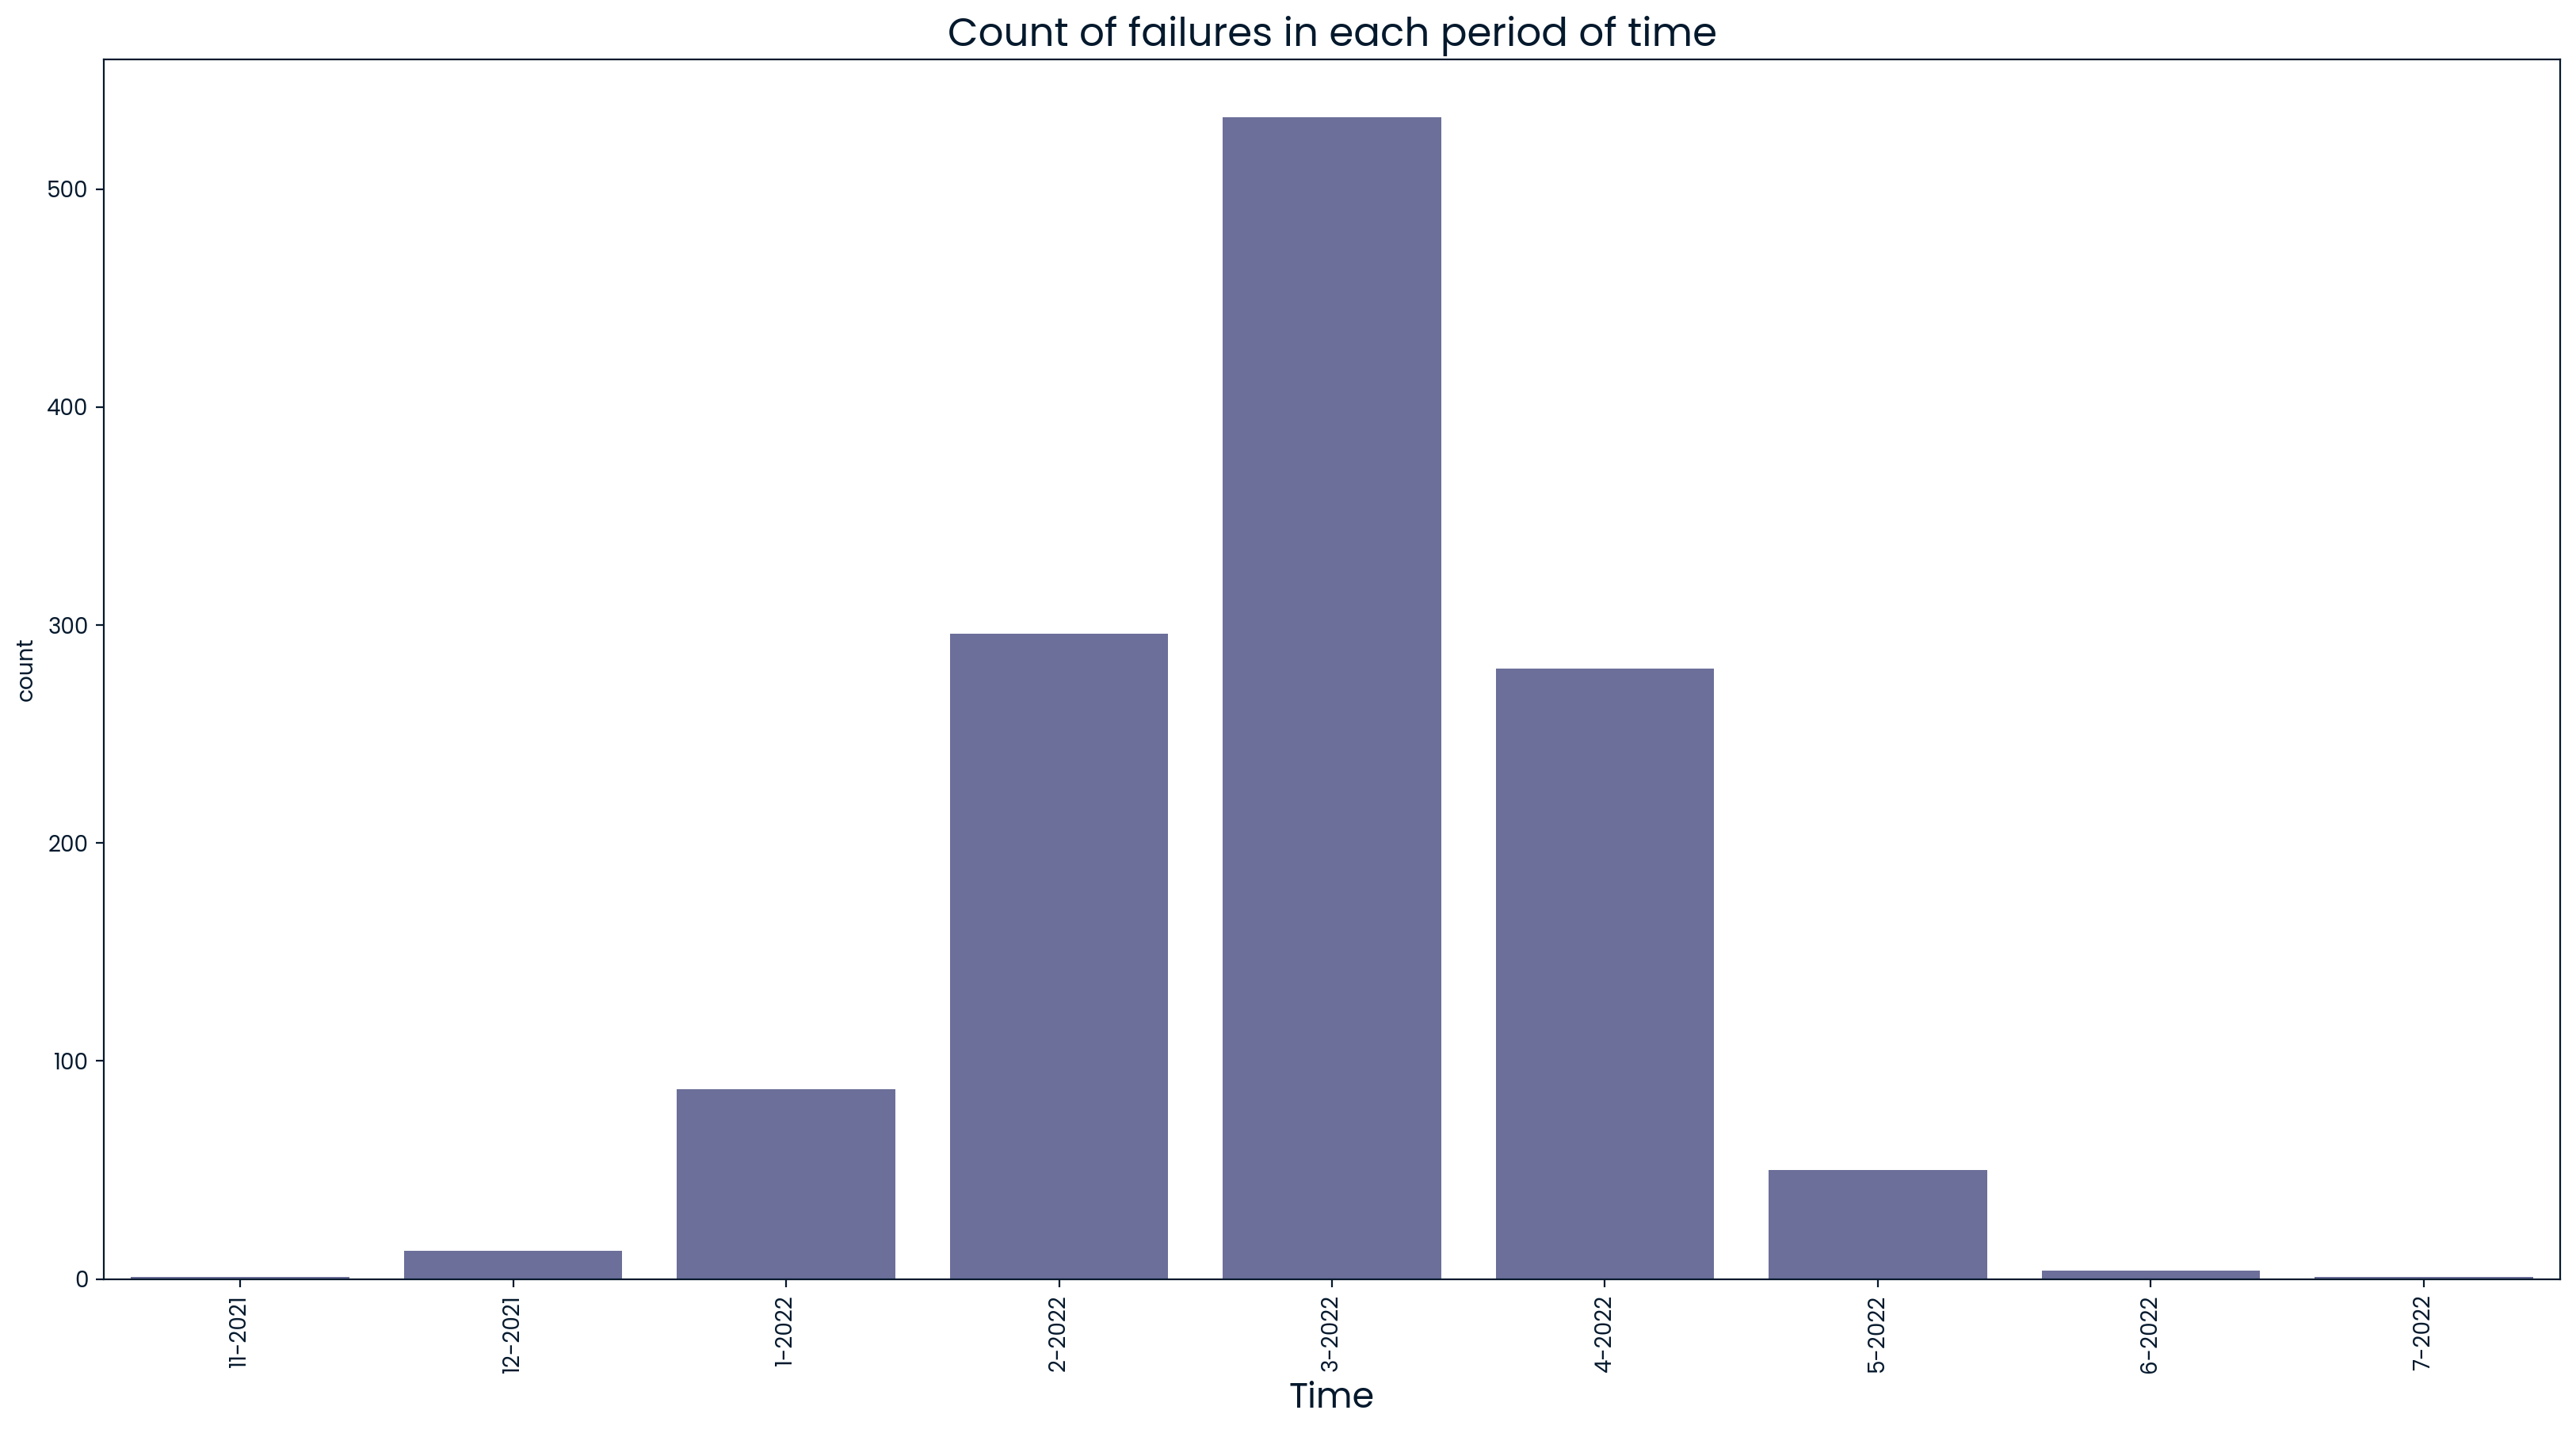

In [235]:
#  visualize count of failures in each month
fig, ax = plt.subplots(1, 1, figsize=(20,10))
sns.barplot(data=machine_failure_month, x='year_month', y='count', ax=ax)
plt.xticks(rotation=90)
plt.xlabel('Time', size=16)
plt.title('Count of failures in each period of time', size=18)
plt.show()

From the bar chart above, we can observe that most counts of failures occurred in February, March, and April, with March having the highest number of cases.

### Numeric variables

[Text(0.5, 1.0, 'The Correlation Heatmap between Numeric Variables')]

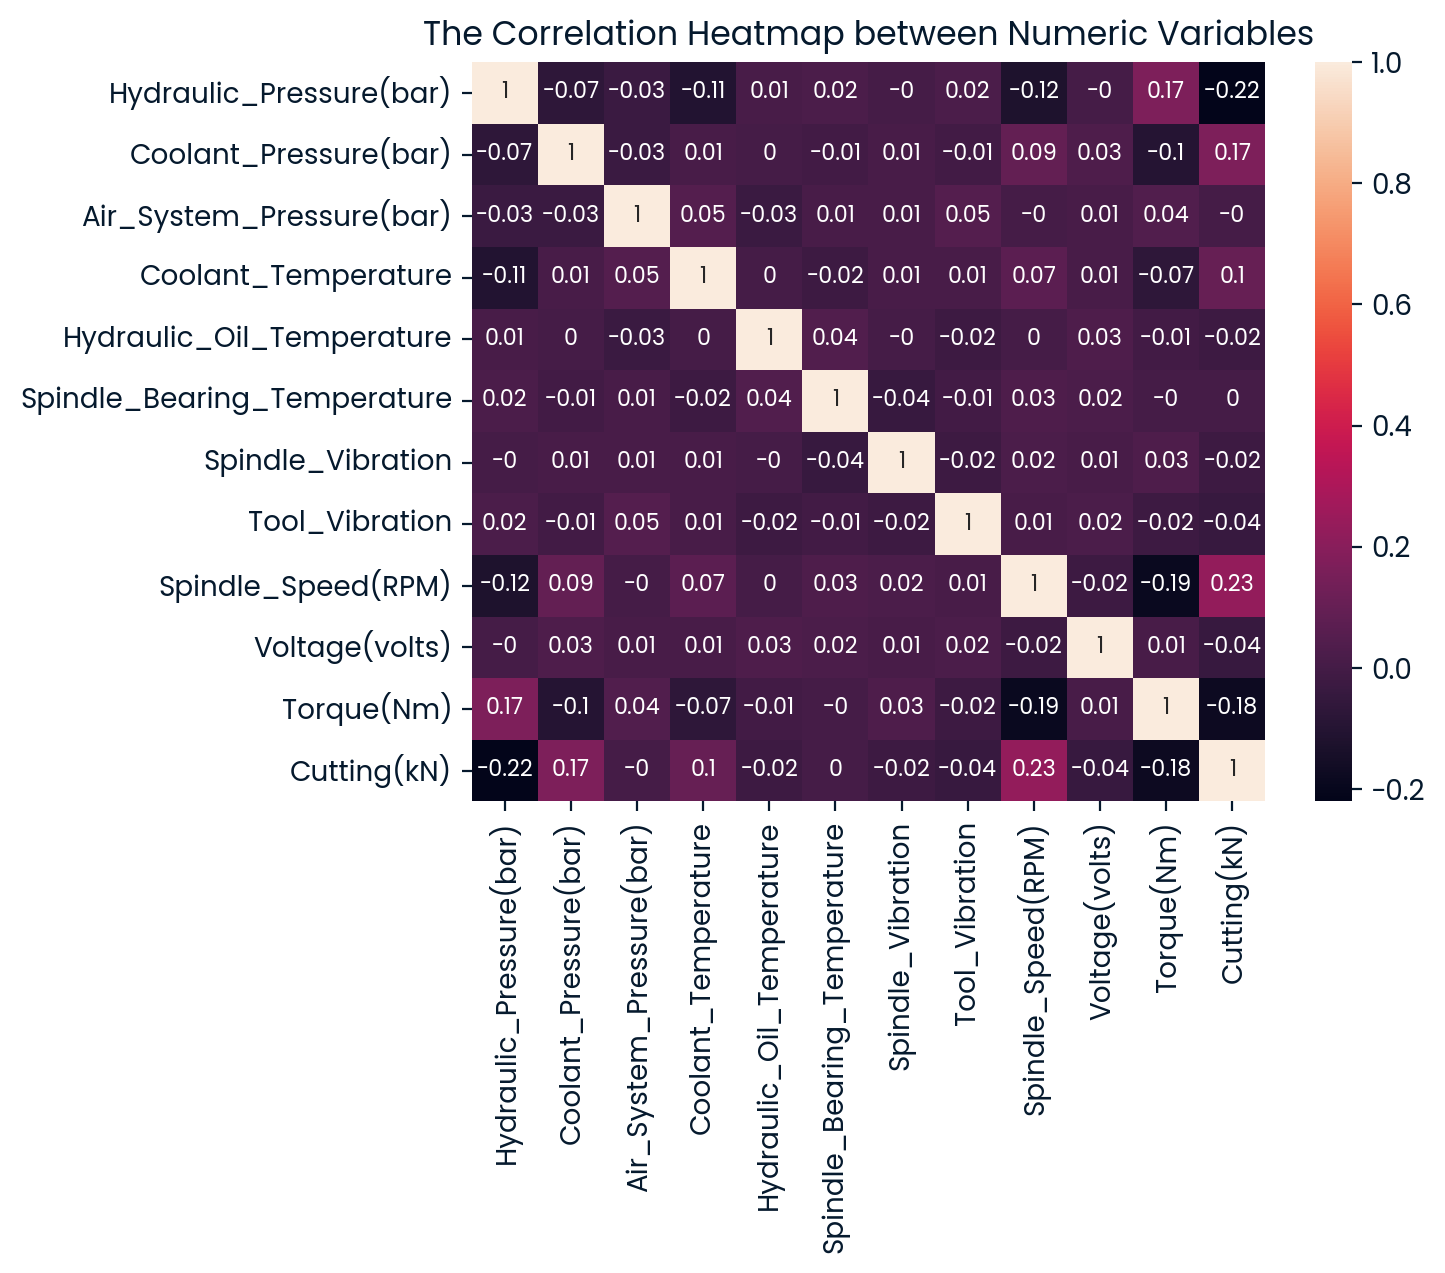

In [236]:
# check the correlation
numeric_df = downtime_clean.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr().round(2), annot=True, annot_kws={"size": 8}).set(title='The Correlation Heatmap between Numeric Variables')

From the heatmap above, we can see that the variables Spindle_Speed (RPM) and Cutting (KN) have a weak positive linear relationship (0.23). Similarly, Hydraulic_Pressure (bar) and Torque (Nm) also exhibit a weak positive linear relationship (0.17), as do Coolant_Pressure (bar) and Cutting (KN) (0.17). Additionally, there is a weak negative linear relationship (-0.22) between the Hydraulic_Pressure (bar) and Cutting (KN) variables.

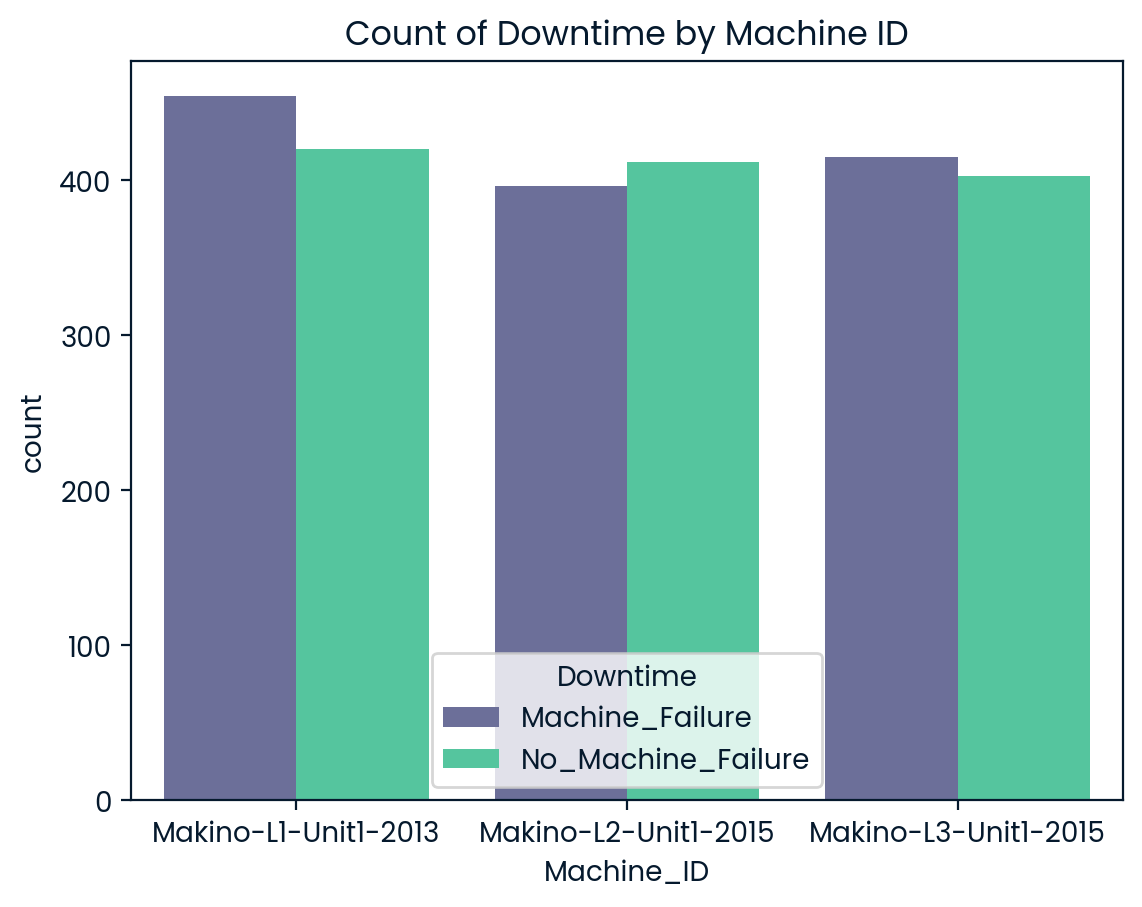

In [237]:
# visualize count of Downtime by Machine ID
machine_id_counts = downtime_clean.groupby(['Machine_ID', 'Downtime']).size().reset_index(name='count')
sns.barplot(data=machine_id_counts, x='Machine_ID', y='count', hue='Downtime')
plt.title('Count of Downtime by Machine ID')
plt.xticks(rotation=0)
plt.xlabel('Machine_ID')
plt.show()

From the plot above, we can observe that the most failures occur on the Makino-L1-Unit-2013 machine ID.

### Log Transformation of variables: Hydraulic_Pressure, Coolant_Pressure, Coolant_Temperature, Spindle_Speed, Torque(Nm) and Cutting(kN).

In [238]:
# log transformation
list_cols = ['Hydraulic_Pressure(bar)', 'Coolant_Pressure(bar)', 'Coolant_Temperature', 'Spindle_Speed(RPM)', 'Torque(Nm)', 'Cutting(kN)']
for col_log in list_cols:
    downtime_clean[col_log] = downtime_clean[col_log].apply(lambda x: x+1 if x <= 0 else x)
    downtime_clean[f"{col_log}_log"] = np.log(downtime_clean[col_log])

# check the data frame after transformation
downtime_clean.head()

,Date,Machine_ID,Assembly_Line_No,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature,Spindle_Bearing_Temperature,Spindle_Vibration,Tool_Vibration,Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Downtime,Hydraulic_Pressure(bar)_log,Coolant_Pressure(bar)_log,Coolant_Temperature_log,Spindle_Speed(RPM)_log,Torque(Nm)_log,Cutting(kN)_log
0,2021-12-31,Makino-L1-Unit1-2013,Shopfloor-L1,71.04,6.933725,6.284965,25.6,46.0,33.4,1.291,26.492,25892.0,335.0,24.055326,3.58,Machine_Failure,4.263243,1.936397,3.242592,10.161689,3.180356,1.275363
1,2021-12-31,Makino-L1-Unit1-2013,Shopfloor-L1,125.33,4.936892,6.196733,35.3,47.4,34.6,1.382,25.274,19856.0,368.0,14.202890,2.68,Machine_Failure,4.830950,1.596736,3.563883,9.896262,2.653445,0.985817
2,2021-12-31,Makino-L3-Unit1-2015,Shopfloor-L3,71.12,6.839413,6.655448,13.1,40.7,33.0,1.319,30.608,19851.0,325.0,24.049267,3.55,Machine_Failure,4.264369,1.922702,2.572612,9.896010,3.180105,1.266948
3,2022-05-31,Makino-L2-Unit1-2015,Shopfloor-L2,139.34,4.574382,6.560394,24.4,44.2,40.6,0.618,30.791,18461.0,360.0,25.860029,3.55,Machine_Failure,4.936917,1.520472,3.194583,9.823416,3.252699,1.266948
4,2022-03-31,Makino-L1-Unit1-2013,Shopfloor-L1,60.51,6.893182,6.141238,4.1,47.3,31.4,0.983,25.516,26526.0,354.0,25.515874,3.55,Machine_Failure,4.102809,1.930533,1.410987,10.185881,3.239301,1.266948


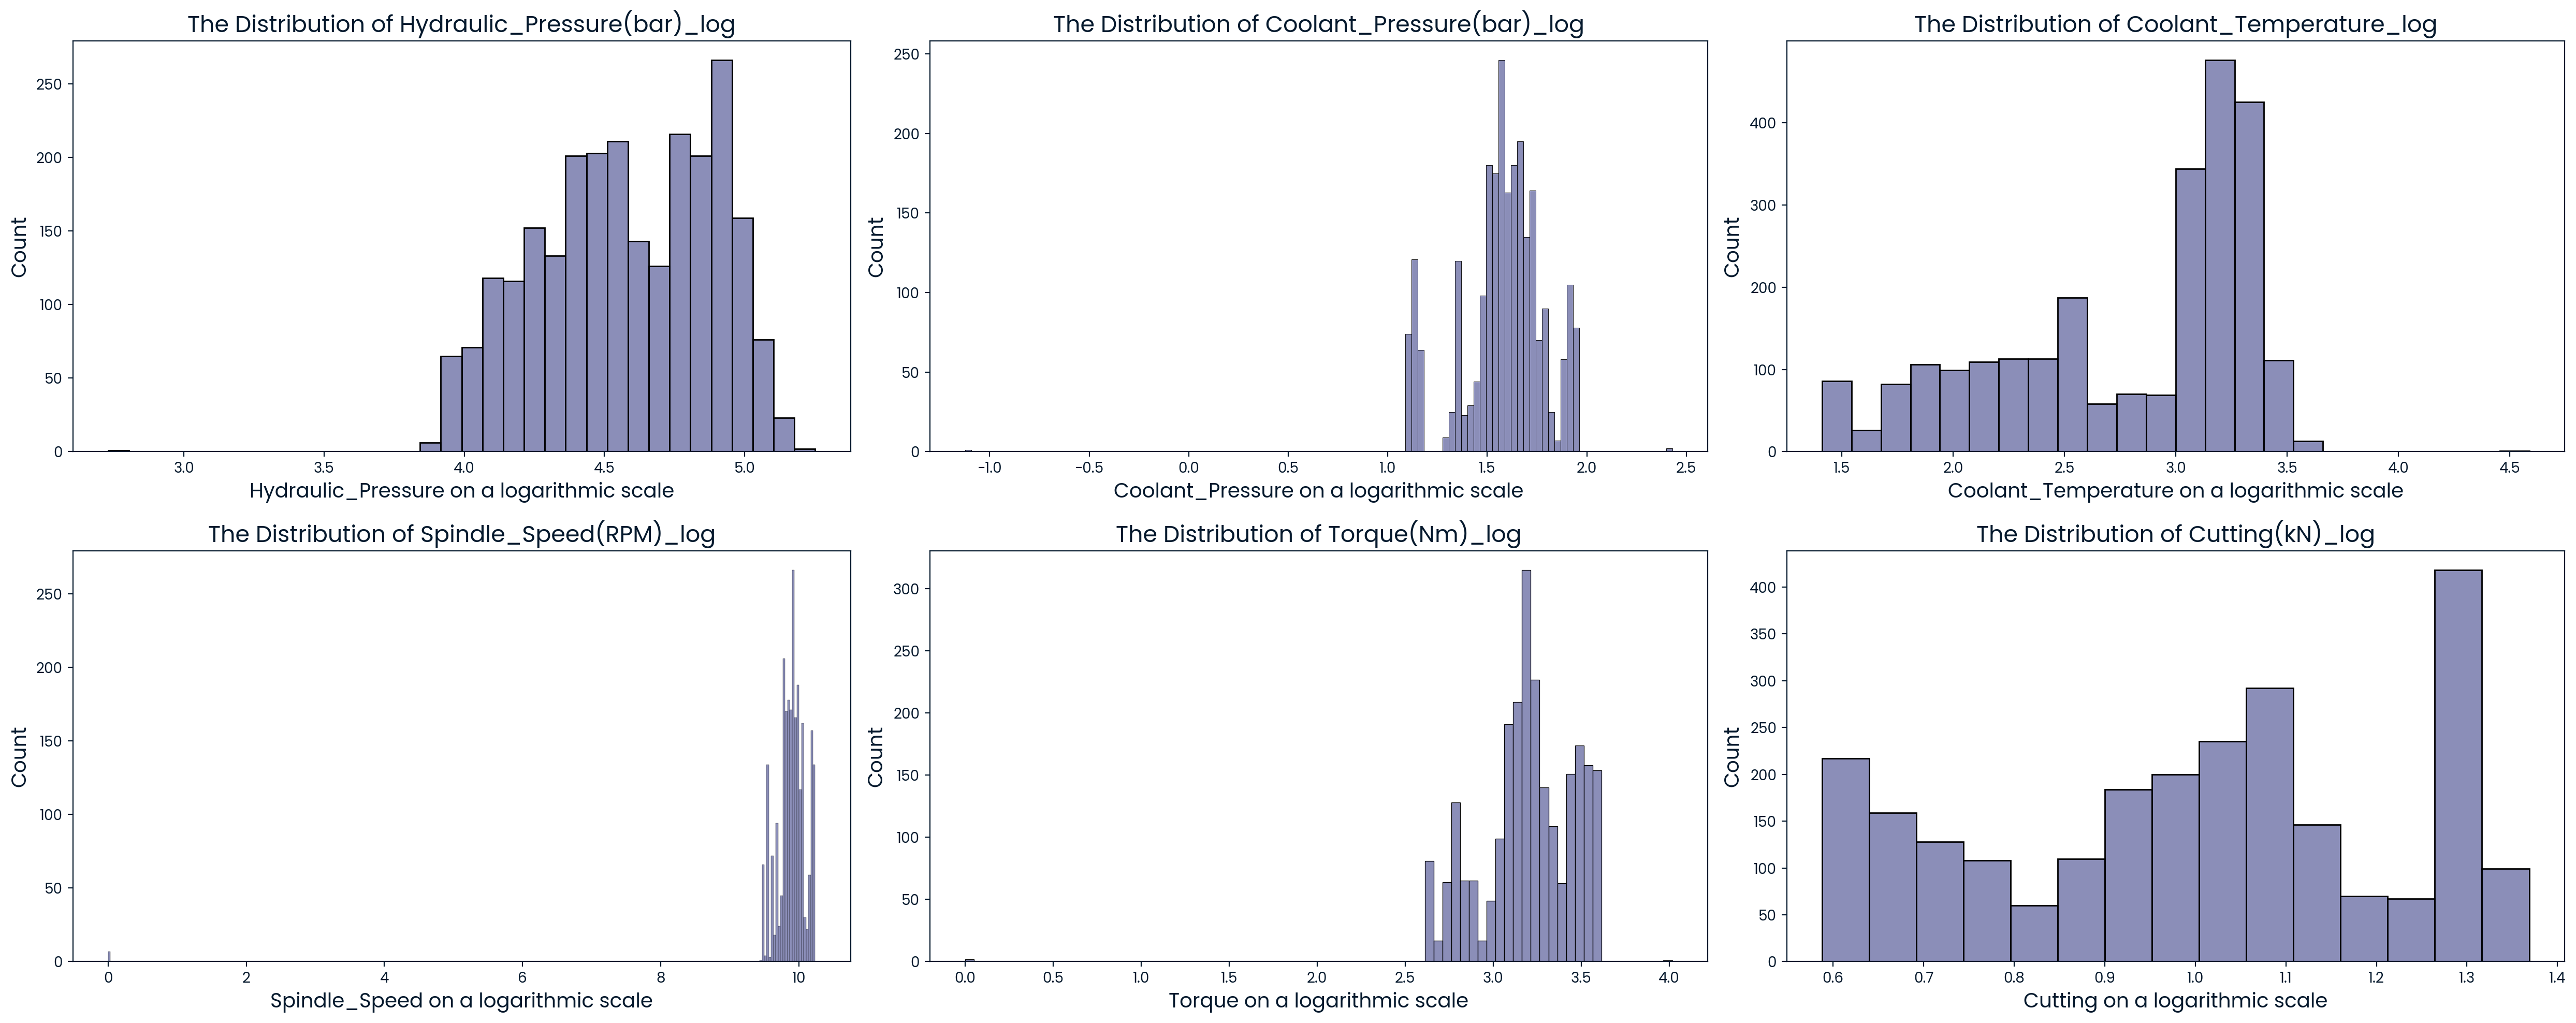

In [239]:
# visualize the distribution of Hydraulic_Pressure, Coolant_Pressure, Coolant_Temperature, Spindle_Speed, Torque(Nm) and Cutting(kN) on a logaritmic scale

list_cols_log = ['Hydraulic_Pressure(bar)_log', 'Coolant_Pressure(bar)_log', 'Coolant_Temperature_log', 'Spindle_Speed(RPM)_log', 'Torque(Nm)_log', 'Cutting(kN)_log']

fig, axes = plt.subplots(2, 3, figsize=(25,10))
axes = axes.flatten()  # Flatten the 2D array of axes to 1D for easier indexing
for ii, cols in enumerate(list_cols_log):
    sns.histplot(x=cols, data=downtime_clean, ax=axes[ii])
    axes[ii].set_title(f'The Distribution of {cols}', fontsize=16)
    axes[ii].set_xlabel(f'{cols}', fontsize=14)
    axes[0].set_xlabel('Hydraulic_Pressure on a logarithmic scale', fontsize=14)
    axes[1].set_xlabel('Coolant_Pressure on a logarithmic scale', fontsize=14) 
    axes[2].set_xlabel('Coolant_Temperature on a logarithmic scale', fontsize=14) 
    axes[3].set_xlabel('Spindle_Speed on a logarithmic scale', fontsize=14) 
    axes[4].set_xlabel('Torque on a logarithmic scale', fontsize=14) 
    axes[5].set_xlabel('Cutting on a logarithmic scale', fontsize=14)
    axes[ii].set_ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()

In [240]:
# extract month from 'Date' variable
downtime_clean['Month'] = downtime_clean['Date'].dt.month
downtime_clean['Month'] = downtime_clean['Month'].astype('category')
downtime_clean.head()

,Date,Machine_ID,Assembly_Line_No,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature,Spindle_Bearing_Temperature,Spindle_Vibration,Tool_Vibration,Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Downtime,Hydraulic_Pressure(bar)_log,Coolant_Pressure(bar)_log,Coolant_Temperature_log,Spindle_Speed(RPM)_log,Torque(Nm)_log,Cutting(kN)_log,Month
0,2021-12-31,Makino-L1-Unit1-2013,Shopfloor-L1,71.04,6.933725,6.284965,25.6,46.0,33.4,1.291,26.492,25892.0,335.0,24.055326,3.58,Machine_Failure,4.263243,1.936397,3.242592,10.161689,3.180356,1.275363,12
1,2021-12-31,Makino-L1-Unit1-2013,Shopfloor-L1,125.33,4.936892,6.196733,35.3,47.4,34.6,1.382,25.274,19856.0,368.0,14.202890,2.68,Machine_Failure,4.830950,1.596736,3.563883,9.896262,2.653445,0.985817,12
2,2021-12-31,Makino-L3-Unit1-2015,Shopfloor-L3,71.12,6.839413,6.655448,13.1,40.7,33.0,1.319,30.608,19851.0,325.0,24.049267,3.55,Machine_Failure,4.264369,1.922702,2.572612,9.896010,3.180105,1.266948,12
3,2022-05-31,Makino-L2-Unit1-2015,Shopfloor-L2,139.34,4.574382,6.560394,24.4,44.2,40.6,0.618,30.791,18461.0,360.0,25.860029,3.55,Machine_Failure,4.936917,1.520472,3.194583,9.823416,3.252699,1.266948,5
4,2022-03-31,Makino-L1-Unit1-2013,Shopfloor-L1,60.51,6.893182,6.141238,4.1,47.3,31.4,0.983,25.516,26526.0,354.0,25.515874,3.55,Machine_Failure,4.102809,1.930533,1.410987,10.185881,3.239301,1.266948,3


# Model Fitting & Evaluation

Predicting machine failure is a classification problem in machine learning.

I chose the Decision Tree Classifier and combined it with a Bagging Classifier model. Decision trees can capture non-linear patterns and efficiently handle both numeric and categorical features. They offer an intuitive visual representation and provide insights into feature importance. However, individual decision trees can be prone to overfitting. To address this, using a Bagging Classifier can enhance performance by reducing overfitting and variance. Bagging, which stands for Bootstrap Aggregating, creates multiple samples from the training data and builds an independent decision tree for each sample, then averages their predictions for better accuracy and robustness.

When analyzing machine failure scenarios, it's essential to focus on metrics that prioritize catching failures (positive cases) accurately because the costs associated with undetected machine failures can be significant.
 Recall (also known as sensitivity or true positive rate) for the positive class, in this case 'Machine_Failure'. 
  Precision measures the proportion of positive identifications that were actually correct.
F1-score is the harmonic mean of Precision and Recall.
  Accuracy is the proportion of all predictions that the model got correct.

  I tuned the model with GridSearchCV using F1 as the scoring metric. Recall is the metric that matters most here, but tuning on recall alone is a trap: a model that calls every reading a failure gets a perfect recall of 1.0 and is useless. F1 keeps both sides honest.

# Prepare data for modelling

To enable modeling, we have chosen Machine_ID, Hydraulic_Pressure(bar)_log, Coolant_Pressure(bar)_log, Air_System_Pressure(bar), Coolant_Temperature_log, Hydraulic_Oil_Temperature, Spindle_Bearing_Temperature, Spindle_Vibration, Tool_Vibration, Spindle_Speed(RPM)_log, Voltage(volts), Torque(Nm)_log, Cutting(kN)_log, and Month as features, with Downtime as the target variable.

Everything that has to learn something from the data is placed inside one pipeline:

- The missing values are filled with the median for numeric features and the most frequent value for categorical ones
- The numeric features are scaled
- The categorical variables are converted into numeric features
- The data is split into training and test sets before any of this happens

The pipeline matters more than it looks. Because the filling and the scaling sit inside it, they are calculated again on each fold of the cross-validation, and only on the training part of that fold. The test rows never take part in it.

I did not upsample the minority class. The classes are 1265 against 1235, so there is almost nothing to balance.

In [241]:
# apply the mapping to the 'Downtime' column
downtime_clean['Downtime'] = downtime_clean['Downtime'].replace({"Machine_Failure":1, "No_Machine_Failure":0})
downtime_clean['Downtime'] = downtime_clean['Downtime'].astype(int)

In [242]:
# creating the data frame for modeling
df = downtime_clean[['Machine_ID', 'Hydraulic_Pressure(bar)_log', 'Coolant_Pressure(bar)_log', 'Air_System_Pressure(bar)', 'Coolant_Temperature_log', 'Hydraulic_Oil_Temperature', 'Spindle_Bearing_Temperature', 'Spindle_Vibration', 'Tool_Vibration', 'Spindle_Speed(RPM)_log', 'Voltage(volts)', 'Torque(Nm)_log', 'Cutting(kN)_log', 'Month', 'Downtime']]

In [243]:
# check the missing values and data types
print("\nMissing values: \n", df.isna().sum())
print(df.dtypes)


Missing values: 
 Machine_ID                      0
Hydraulic_Pressure(bar)_log    11
Coolant_Pressure(bar)_log      19
Air_System_Pressure(bar)       17
Coolant_Temperature_log        12
Hydraulic_Oil_Temperature      16
Spindle_Bearing_Temperature     7
Spindle_Vibration              12
Tool_Vibration                 11
Spindle_Speed(RPM)_log          6
Voltage(volts)                  6
Torque(Nm)_log                 21
Cutting(kN)_log                 7
Month                           0
Downtime                        0
dtype: int64
Machine_ID                     category
Hydraulic_Pressure(bar)_log     float64
Coolant_Pressure(bar)_log       float64
Air_System_Pressure(bar)        float64
Coolant_Temperature_log         float64
Hydraulic_Oil_Temperature       float64
Spindle_Bearing_Temperature     float64
Spindle_Vibration               float64
Tool_Vibration                  float64
Spindle_Speed(RPM)_log          float64
Voltage(volts)                  float64
Torque(Nm)_log    

In [244]:
num_cols = ['Hydraulic_Pressure(bar)_log', 'Coolant_Pressure(bar)_log',
            'Air_System_Pressure(bar)', 'Coolant_Temperature_log',
            'Hydraulic_Oil_Temperature', 'Spindle_Bearing_Temperature',
            'Spindle_Vibration', 'Tool_Vibration', 'Spindle_Speed(RPM)_log',
            'Voltage(volts)', 'Torque(Nm)_log', 'Cutting(kN)_log']
cat_cols = ['Machine_ID', 'Month']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh',  OneHotEncoder(drop='first',
                                            handle_unknown='ignore'))]), cat_cols),
])

clf = Pipeline([
    ('prep',  preprocessor),
    ('model', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42), random_state=42)),
])

param_grid = {
    'model__estimator__max_depth':         [None, 5, 10, 20],
    'model__estimator__criterion':         ['entropy', 'gini', 'log_loss'],
    'model__estimator__min_samples_split': [2, 5, 10],
    'model__estimator__min_samples_leaf':  [1, 2, 4],
    'model__estimator__max_features':      [None, 'sqrt', 'log2'],
}

In [245]:
X = df.drop('Downtime', axis=1)
y = df['Downtime']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

gs = GridSearchCV(clf, param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=0)
gs.fit(X_train, y_train)

print("best params:", gs.best_params_)
print("best CV f1:", round(gs.best_score_, 4))

pred = gs.best_estimator_.predict(X_test)
for name, fn in [("recall", recall_score), ("precision", precision_score),
                 ("f1", f1_score), ("accuracy", accuracy_score)]:
    print(f"{name}: {fn(y_test, pred):.4f}")

best params: {'model__estimator__criterion': 'entropy', 'model__estimator__max_depth': None, 'model__estimator__max_features': 'sqrt', 'model__estimator__min_samples_leaf': 1, 'model__estimator__min_samples_split': 10}
best CV f1: 0.9822
recall: 0.9723
precision: 0.9685
f1: 0.9704
accuracy: 0.9700


### Bagging Classifier with Decision Trees as the base estimator

This model correctly predicts 'Machine_Failure' in 97.2% of the cases where there actually is a 'Machine_Failure'. Out of all the cases where the model predicted 'Machine_Failure', 96.9% were correct predictions. An F1 score of 97% means the model keeps a good balance between Precision and Recall. The Accuracy of 97% is the proportion of all predictions that the model got correct.

These numbers are lower than the ones I got in my first version, and that is on purpose. In the first version I filled the missing values with the median and the mean taken separately for each class of 'Downtime'. The filled values then carried a piece of the answer inside them, and the model got a hint it would never have in real use. Removing that hint costs about 1.5 points of F1. The numbers above are the honest ones.

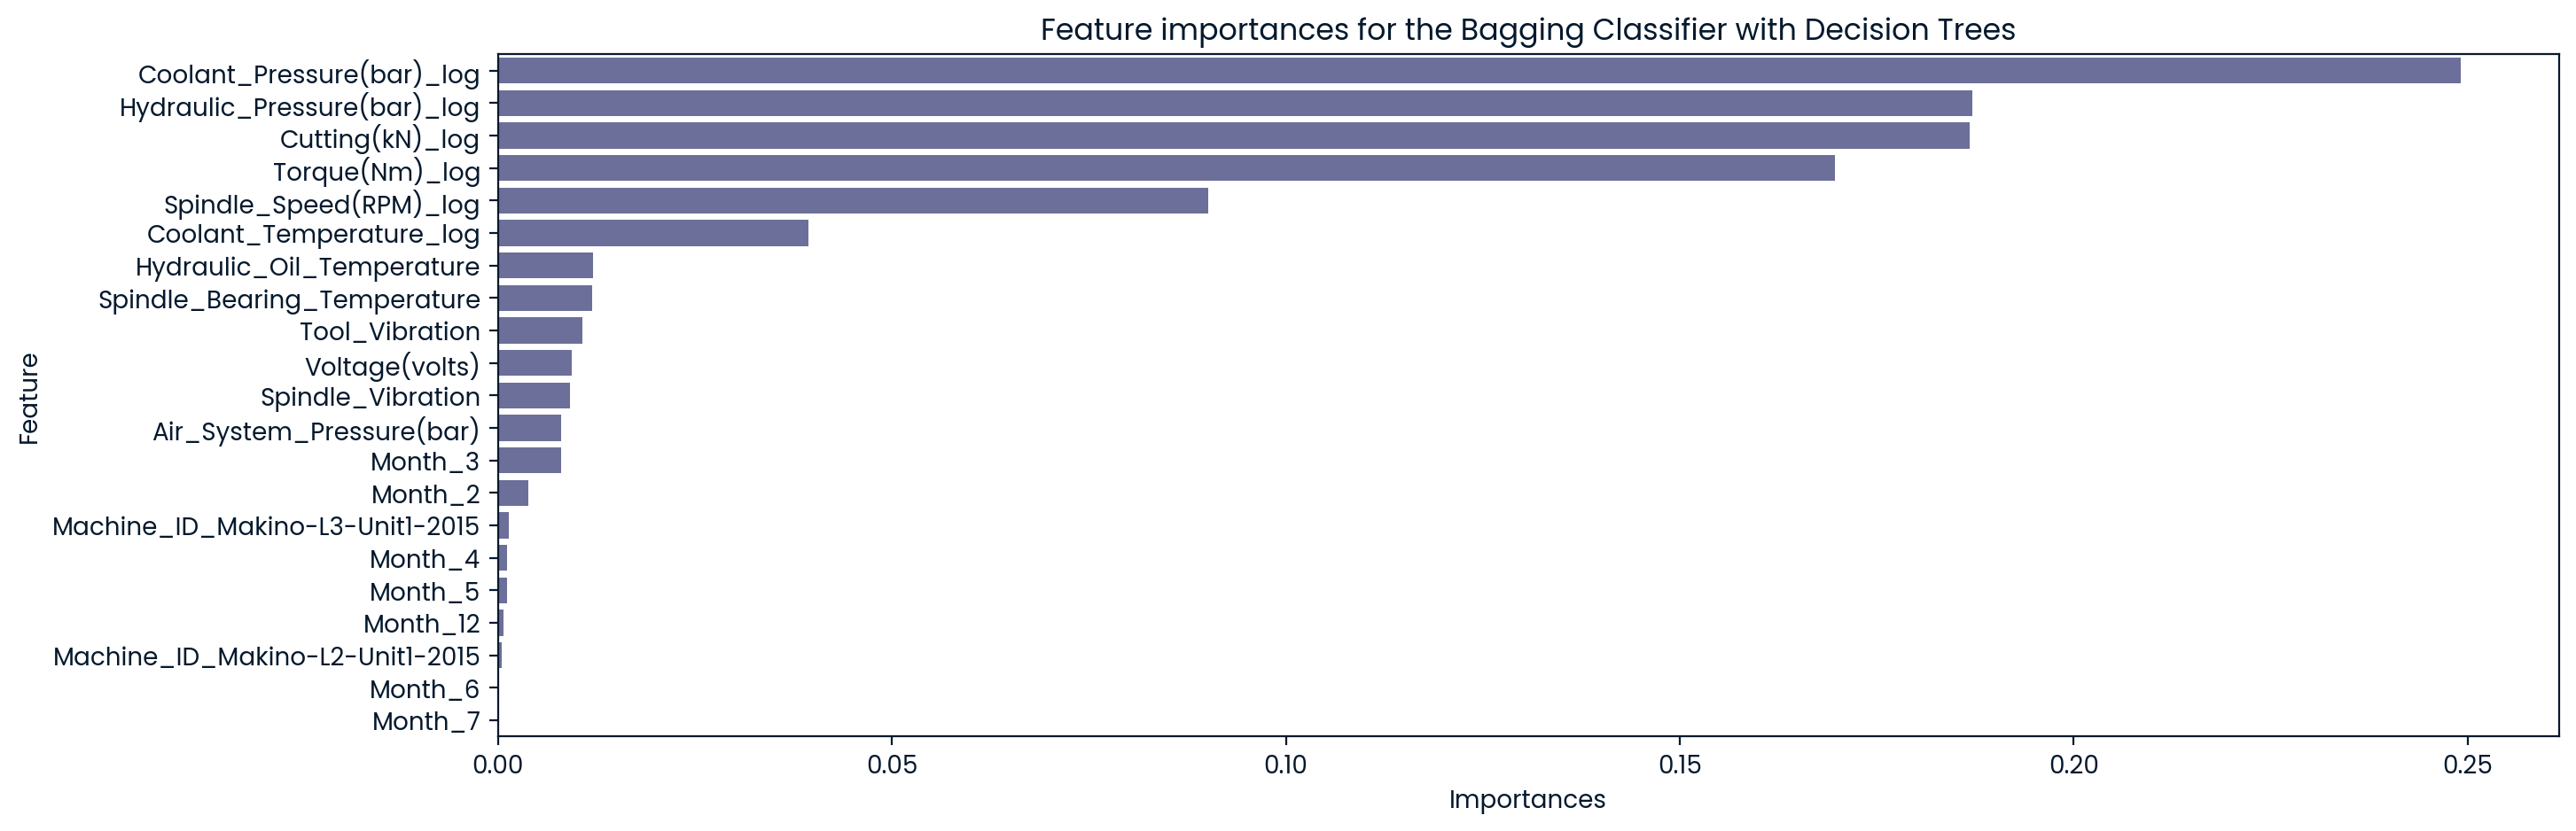

In [246]:
best_model = gs.best_estimator_
bag        = best_model.named_steps['model']

feat_names = pd.Index(best_model.named_steps['prep'].get_feature_names_out())
feat_names = feat_names.str.replace('num__', '').str.replace('cat__', '')

importances = np.mean([t.feature_importances_ for t in bag.estimators_], axis=0)
importance_dt_es = pd.DataFrame(
    {'Feature': feat_names, 'Importances': importances}
).sort_values('Importances', ascending=False)

plt.figure(figsize=(15, 5))
sns.barplot(x='Importances', y='Feature', data=importance_dt_es)
plt.title('Feature importances for the Bagging Classifier with Decision Trees')
plt.show()

The most important features are Coolant Pressure, Hydraulic Pressure, Cutting, Torque, Spindle Speed and Coolant Temperature, all presented on a logarithmic scale. The 'Month' and 'Machine_ID' features sit at the very bottom of the plot with almost no weight, which means the model barely uses them.

# How much can I trust these numbers?

97% is a high score, and a high score is a reason to check the data rather than to celebrate. A model can reach it honestly, or it can reach it because the test set is not really new to it. Before I write any conclusions, I want to rule out the second case.

Each row here is one reading of one machine on one day, and there are about six readings per machine per day. If readings taken close in time look almost the same, then a random split puts near-copies of the same situation into training and into test, and the model is partly recognising rows it has already seen.

So I checked two things: whether readings of the same machine-day carry the same label, and whether the failure rate of one day says anything about the next day.


In [247]:
# Robust label + autocorrelation test 
d = downtime_clean.copy()
d['Date'] = pd.to_datetime(d['Date'], dayfirst=True)

print("Downtime dtype was:", d['Downtime'].dtype)
lab = d['Downtime']
if lab.dtype.name in ('category', 'object'):
    lab = lab.astype(str).map({'Machine_Failure': 1, 'No_Machine_Failure': 0,
                               '1': 1, '0': 0})
d['y'] = lab.astype(int)
print("label counts:", d['y'].value_counts().to_dict())

g = d.groupby(['Machine_ID', 'Date'], observed=True)['y'].agg(n='size', mean='mean')
pure = ((g['mean'] == 0) | (g['mean'] == 1)).mean()
print(f"\nreadings per machine-day: {g['n'].mean():.1f}")
print(f"machine-days with one label only: {pure:.3f}")

print("\nlag-1 correlation of the daily failure rate:")
for m, gm in d.groupby('Machine_ID', observed=True):
    daily = gm.groupby('Date', observed=True)['y'].mean().sort_index()
    print(f"  {m}: {daily.autocorr(1):.3f}")

Downtime dtype was: int64
label counts: {1: 1265, 0: 1235}

readings per machine-day: 6.0
machine-days with one label only: 0.288

lag-1 correlation of the daily failure rate:
  Makino-L1-Unit1-2013: -0.063
  Makino-L2-Unit1-2015: -0.130
  Makino-L3-Unit1-2015: -0.022


In [248]:
# Is the "pure day" effect real, or just days with few readings? 
tmp = g.reset_index()
tmp['pure'] = (tmp['mean'] == 0) | (tmp['mean'] == 1)
print(tmp.groupby('n')['pure'].agg(days='size', pure_share='mean'))

# Rebuild X / y / groups 
X = df.drop('Downtime', axis=1)
y = df['Downtime'].astype(int)
dates  = pd.to_datetime(downtime_clean['Date'], dayfirst=True).loc[X.index]
groups = downtime_clean['Machine_ID'].astype(str).loc[X.index] + '_' + dates.dt.strftime('%Y-%m-%d')

def evaluate(Xtr, Xte, ytr, yte, label):
    gs_ = GridSearchCV(clf, param_grid, cv=5, scoring='f1', n_jobs=-1)
    gs_.fit(Xtr, ytr)
    p = gs_.best_estimator_.predict(Xte)
    print(f"\n{label}  (train={len(Xtr)}, test={len(Xte)})")
    for nm, fn in [("recall", recall_score), ("precision", precision_score),
                   ("f1", f1_score), ("accuracy", accuracy_score)]:
        print(f"   {nm}: {fn(yte, p):.4f}")

# A. group split — all readings of one machine-day stay together
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups))
evaluate(X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], "A. group split by machine-day")

# B. temporal split — train on the earlier 80% of days, test on the rest
cut = dates.quantile(0.8)
m = dates <= cut
print("\ncut date:", cut.date())
evaluate(X[m], X[~m], y[m], y[~m], "B. temporal split")

    days  pure_share
n                   
1     76    1.000000
2     42    0.690476
3     36    0.194444
4     40    0.125000
5     29    0.000000
6     27    0.037037
7     30    0.066667
8     17    0.000000
9     29    0.000000
10    16    0.000000
11    21    0.000000
12    15    0.000000
13    10    0.000000
14     6    0.000000
15     7    0.000000
16     8    0.000000
17     2    0.000000
18     1    0.000000
19     1    0.000000
20     1    0.000000
22     1    0.000000
27     1    0.000000

A. group split by machine-day  (train=1997, test=503)
   recall: 0.9881
   precision: 0.9728
   f1: 0.9804
   accuracy: 0.9801

cut date: 2022-04-06

B. temporal split  (train=2025, test=475)
   recall: 0.9915
   precision: 0.9831
   f1: 0.9873
   accuracy: 0.9874


Both checks come back clean.

The share of machine-days where every reading has the same label looked high at first (0.288), but the breakdown by the number of readings explains it. Days with a single reading are pure by definition, and there are 76 of them. From three readings per day onwards the share sits at chance level or below — 0.194 where chance is 0.25, 0.125 where chance is 0.125, 0.037 for six readings. So readings inside one day do not stick together.

The day-to-day correlation of the failure rate is -0.063, -0.130 and -0.022 for the three machines. That is zero. Yesterday says nothing about today.

Then I rebuilt the model with two other splits and compared them with the random one:

| split | recall | precision | f1 | accuracy |
|---|---|---|---|---|
| random | 0.9723 | 0.9685 | 0.9704 | 0.9700 |
| by machine-day | 0.9881 | 0.9728 | 0.9804 | 0.9801 |
| by time | 0.9915 | 0.9831 | 0.9873 | 0.9874 |

The group split keeps all readings of one machine-day on the same side, so the model cannot meet a near-copy of a training row. The time split trains on the first 80% of the period and tests on the last 20%, which is what deployment would actually look like. Both give the same answer as the random split, and the spread of one point on a test set of about 500 rows is five rows. That is noise.

The 97% is real.

In [249]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

for name, model in [
    ("dummy (most frequent)", DummyClassifier(strategy='most_frequent')),
    ("logistic regression",   LogisticRegression(max_iter=2000)),
    ("single decision tree",  DecisionTreeClassifier(max_depth=3, random_state=42)),
]:
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_tr, y_tr)
    p = pipe.predict(X_te)
    print(f"{name:24s} f1={f1_score(y_te, p):.4f}  acc={accuracy_score(y_te, p):.4f}")

dummy (most frequent)    f1=0.6720  acc=0.5060
logistic regression      f1=0.8703  acc=0.8700
single decision tree     f1=0.9476  acc=0.9460


The next question is whether the task needs a model this complicated.

| model | f1 | accuracy |
|---|---|---|
| dummy (always predicts the majority class) | 0.6720 | 0.5060 |
| logistic regression | 0.8703 | 0.8700 |
| single decision tree, depth 3 | 0.9476 | 0.9460 |
| Bagging with Decision Trees | 0.9704 | 0.9700 |

The dummy sits at 0.51 accuracy, which is what balanced classes should give. Logistic regression reaches 0.87, so a straight line through the feature space already separates a lot — but it leaves 13% on the table, and that gap is where the non-linear boundary lives. A single tree of depth 3, small enough to draw on a napkin, gets to 0.95.

The ensemble adds another 2.5 points on top of that tree. It is a real gain and it justifies the model, but it is worth knowing how small the last step is. If someone needed a rule they could read and argue with, the depth-3 tree would be a fair trade.

## Model each machine separately

According to the feature importances plot, 'Machine_ID' has almost no weight, so a separate model per machine may not help. On the other hand, each machine would only get about a third of the data to learn from. Let's test this in practice.

One detail matters for the test to mean anything: both models have to be judged on the same rows. I take the test set of the main model, cut it by machine, and score two models on each piece — one trained on that machine only, and the main one trained on all three.

In [250]:
def run_machine(mid, name):
    tr_m  = X_train[X_train['Machine_ID'] == mid]
    te_m  = X_test[X_test['Machine_ID'] == mid]
    ytr_m = y_train.loc[tr_m.index]
    yte_m = y_test.loc[te_m.index]

    prep_m = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc',  StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh',  OneHotEncoder(drop='first',
                                                handle_unknown='ignore'))]), ['Month']),
    ])
    clf_m = Pipeline([('prep', prep_m),
                      ('model', BaggingClassifier(
                          estimator=DecisionTreeClassifier(random_state=42),
                          random_state=42))])

    gs_m = GridSearchCV(clf_m, param_grid, cv=5, scoring='f1', n_jobs=-1)
    gs_m.fit(tr_m, ytr_m)

    own    = gs_m.best_estimator_.predict(te_m)   # trained on this machine only
    shared = gs.best_estimator_.predict(te_m)     # the all-machines model

    out = []
    for tag, p in [('per-machine', own), ('all machines', shared)]:
        out.append({'machine': name, 'model': tag,
                    'n_train': len(tr_m), 'n_test': len(te_m),
                    'recall': recall_score(yte_m, p),
                    'precision': precision_score(yte_m, p),
                    'f1': f1_score(yte_m, p),
                    'accuracy': accuracy_score(yte_m, p)})
    return out

rows = (run_machine('Makino-L1-Unit1-2013', 'Makino-L1-Unit1-2013')
        + run_machine('Makino-L2-Unit1-2015', 'Makino-L2-Unit1-2015')
        + run_machine('Makino-L3-Unit1-2015', 'Makino-L3-Unit1-2015'))

per_machine = pd.DataFrame(rows).round(4)
print(per_machine.to_string(index=False))

             machine        model  n_train  n_test  recall  precision     f1  accuracy
Makino-L1-Unit1-2013  per-machine      695     179  0.9889     0.9674 0.9780    0.9777
Makino-L1-Unit1-2013 all machines      695     179  0.9778     0.9670 0.9724    0.9721
Makino-L2-Unit1-2015  per-machine      645     163  0.9405     0.9875 0.9634    0.9632
Makino-L2-Unit1-2015 all machines      645     163  0.9405     0.9518 0.9461    0.9448
Makino-L3-Unit1-2015  per-machine      660     158  0.9747     0.9872 0.9809    0.9810
Makino-L3-Unit1-2015 all machines      660     158  1.0000     0.9875 0.9937    0.9937


| machine | rows to train on | per-machine f1 | all-machines f1 |
|---|---|---|---|
| Makino-L1-Unit1-2013 | 695 | 0.9780 | 0.9724 |
| Makino-L2-Unit1-2015 | 645 | 0.9634 | 0.9461 |
| Makino-L3-Unit1-2015 | 660 | 0.9809 | 0.9937 |

The separate model is slightly better on two machines and clearly worse on the third. On average it is 0.974 against 0.971, which is a tie. And each test set here holds 158 to 179 rows, so a difference of one point in F1 is two or three rows. There is nothing to read into it.

My first guess was half right. I expected the separate models to lose because they train on three times less data. They did not lose — 650 rows turned out to be enough. They simply had nothing extra to learn, because there is not much that separates one machine from another in the first place.

The practical conclusion goes the other way from the metrics. Three models mean three things to train, watch and retrain, for no measurable gain. One model for all machines is the right choice.

In [251]:
missing = [c for c in num_cols if c not in downtime_clean.columns]
print("missing in downtime_clean:", missing)

# Build a working frame from df + Date 
work = df[num_cols + ['Machine_ID']].copy()
work['Date'] = pd.to_datetime(downtime_clean['Date'], dayfirst=True).loc[work.index]

lab = df['Downtime']
if lab.dtype.name in ('category', 'object'):
    lab = lab.astype(str).map({'Machine_Failure': 1, 'No_Machine_Failure': 0,
                               '1': 1, '0': 0})
work['y'] = lab.astype(int)

daily = (work.groupby(['Machine_ID', 'Date'], observed=True)[num_cols + ['y']]
             .mean()
             .reset_index()
             .sort_values(['Machine_ID', 'Date']))

daily['y_today'] = (daily['y'] >= 0.5).astype(int)
daily['y_next']  = daily.groupby('Machine_ID', observed=True)['y_today'].shift(-1)
daily = daily.dropna(subset=['y_next'])
daily['y_next'] = daily['y_next'].astype(int)
print("machine-days:", len(daily),
      "| class balance next-day:", daily['y_next'].mean().round(3))

# Same-day detection vs next-day forecasting 
feat = daily[num_cols]
cut  = daily['Date'].quantile(0.8)
mtr  = daily['Date'] <= cut
print("cut date:", cut.date(), "| train:", mtr.sum(), "test:", (~mtr).sum())

for target in ['y_today', 'y_next']:
    t = daily[target]
    print(f"\n--- target: {target} ---")
    for nm, mdl in [("dummy", DummyClassifier(strategy='most_frequent')),
                    ("logistic", LogisticRegression(max_iter=2000)),
                    ("bagging", BaggingClassifier(
                        estimator=DecisionTreeClassifier(random_state=42),
                        random_state=42))]:
        pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                         ('sc',  StandardScaler()),
                         ('m',   mdl)])
        pipe.fit(feat[mtr], t[mtr])
        p = pipe.predict(feat[~mtr])
        print(f"  {nm:10s} f1={f1_score(t[~mtr], p):.4f}  "
              f"acc={accuracy_score(t[~mtr], p):.4f}")

missing in downtime_clean: []
machine-days: 413 | class balance next-day: 0.574
cut date: 2022-04-24 | train: 331 test: 82

--- target: y_today ---
  dummy      f1=0.6557  acc=0.4878
  logistic   f1=0.8101  acc=0.8171
  bagging    f1=0.8684  acc=0.8780

--- target: y_next ---
  dummy      f1=0.6446  acc=0.4756
  logistic   f1=0.6105  acc=0.5488
  bagging    f1=0.5185  acc=0.5244


# Detecting is not predicting

The brief is not quite consistent with itself, and the two things it asks for are worth separating.

The background says the company wants maintenance planned in advance instead of a reaction to a breakdown. That is forecasting. The task itself then asks for a model that works with real-time operational data and detects a likely failure. That is a judgement about the present moment, and it is what everything above does.

So the model does the job as it is literally written. What it does not do is serve the reason the job was asked for. I wanted to know whether this data could, so I tested it.

One detail in the data points the same way. The column description says Downtime tells whether the machine was down on that day, but the label changes between readings of the same day — only 28.8% of machine-days carry a single label, and almost all of those are days with one or two readings. So the label belongs to a reading, not to a day. That is another reason this is a task about the current state.

I averaged the readings to one row per machine per day, and then asked for the same label twice: the state of that day, and the state of the next day. Same features, same models, same split by time.

| target | dummy | logistic | bagging |
|---|---|---|---|
| same day (accuracy) | 0.4878 | 0.8171 | 0.8780 |
| next day (accuracy) | 0.4756 | 0.5488 | 0.5244 |

On the same day the model works. On the next day it is a coin flip — 0.52 against the dummy's 0.48. This is the same thing the lag-1 correlation already said, now measured directly.

So the answer is honest and negative. These readings describe the state a machine is in right now. They carry no signal about the state it will be in tomorrow. A model built on them can tell an operator that something is wrong at this moment, which is useful, but it cannot warn anyone in advance.

That is a property of the data, not of the model. Predicting failure ahead of time would need either readings taken far more often than once a day, or features that accumulate over time — hours since the last service, tool wear, a running count of load cycles. None of those are in this table.


# Recommendations

The model classifies the current state of a machine from its current sensor readings, with an F1 of 0.97 that holds under three different ways of splitting the data. It does not predict failures ahead of time, and the data in this table does not support that.

**1. Deploy it as a real-time check, not as a forecast.**
Feed it live readings and let it flag a machine whose state looks like a failure. This is useful on its own — it catches a bad state faster and more consistently than a person watching dials. But it must not be sold as early warning, because it gives none.

**2. Collect the data that a forecast would need.**
The next-day test fails because nothing in this table accumulates over time. To predict a failure before it happens, the data has to carry history: hours run since the last service, tool wear, number of load cycles, the trend of a reading rather than its value. Readings taken every few minutes instead of a few times a day would also help. This is a data collection task, not a modelling task.

**3. Watch for drift.**
Retrain on recent data and compare the new scores with the ones here. The time split already gives a baseline for what a healthy score looks like on unseen later data.

**4. Keep one model for all three machines.**
Separate models gave no gain and triple the maintenance. Revisit this only if a new machine behaves clearly differently from the rest.

**5. Keep all preprocessing inside the pipeline.**
This project started with the missing values filled by class, and that quietly added 1.5 points of F1 that were not real. Anything that learns from the data — filling, scaling, encoding — belongs inside the pipeline where the cross-validation can keep it honest.

# What I learned from this project

The first version of this notebook reported 98% and I believed it. Three checks later the number is 97%, and the difference is not the interesting part — the interesting part is that I now know why it is 97% and what it is worth.

Two of my own hypotheses turned out to be wrong along the way. I thought readings from the same day would stick together, and they do not. I thought there would be drift over the eight months of data, and there is none. Being wrong twice was still worth the time, because the alternative was publishing a number I could not defend.

And the main finding is one I did not expect to make: the goal behind the task — maintenance planned in advance — cannot be reached with this data. Not because the model is too weak, but because the readings hold no information about the future. Saying so is more useful than a high score would have been.